# P2 · Boiling point: one-shot ten-step workflow with self-consistency

This notebook predicts a molecule's **reported boiling point in kelvin from its SMILES string** and walks through all ten steps of the applied machine-learning workflow from [01 · Ten steps in prompts](../../../01_Ten_Steps_in_Prompts.ipynb). It was generated and executed from one detailed prompt ([prompt file](../prompts/P2_one_shot_prompt.txt)). Every step is populated; there are no exercises left to complete. Artifacts are saved under `01_boiling_point/outputs/bp_one_shot_p2_1VC/`.

<h1 style="color:#1D4E89;">Step 0: Conditioning the Coding Assistant</h1>

It helps to start by giving a coding assistant context for the full project. This makes later prompts easier and usually leads to more consistent code. Here the whole project was described in **one** prompt instead of a sequence of step-by-step prompts.


### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


<h3 style="color:#B05E27;">What the single prompt supplied</h3>

The prompt conditioned the assistant with:

- **Role:** a chemistry-aware machine-learning practitioner who is also a clear teacher.
- **Repository context:** read `AGENTS.md`, `README.md`, `SETUP_GUIDE.md`, `pyproject.toml` and the module README first; use the locked UV environment; follow the ten-step template's headings and "Code Summary" pattern.
- **Data contract:** prefer the NIST acquisition Parquet, otherwise the packaged fallback; establish units from provenance; SMILES is the only model input.
- **Rules of sound practice:** no leakage, training-only preprocessing, molecule-disjoint splits, a sealed test set, fair comparisons and honest reporting.
- **A working approach:** plan first, build and run one step at a time, add assertions where errors would be silent, record assumptions, stay within a 10–15 minute CPU budget.
- **A decision strategy:** self-consistency at six key decision points (below).

The step-by-step template asks you to wait for a new prompt at each step. In this one-shot run the assistant populated and executed every step itself, so read it as a worked demonstration of the workflow, not as a prescription.


<h3 style="color:#B05E27;">Self-consistency as a decision strategy</h3>

[Wang et al. (2023), *Self-Consistency Improves Chain of Thought Reasoning in Language Models*](https://arxiv.org/abs/2203.11171) showed that sampling several **diverse reasoning paths** to the same question and keeping the answer most paths agree on is more reliable than trusting a single chain of reasoning. Agreement is evidence; disagreement signals uncertainty.

This notebook adapts the idea to six workflow decisions: (a) the cleaning policy, (b) the split design, (c) the molecular representation, (d) the candidate algorithms, (e) the Step 9 improvement and (f) whether the goal was met. For each, three short paths reason from different viewpoints:

| Path | Viewpoint |
|---|---|
| **P1 · Physical chemistry** | intermolecular forces: size/polarizability, hydrogen bonding, polarity, shape |
| **P2 · Statistics / ML** | dataset size, bias–variance, representation capacity, runtime |
| **P3 · Skeptical reviewer** | leakage, unit errors, failure modes, over-claiming |

Each decision is shown as a table (path, reasoning, answer) followed by the chosen option, the agreement level and how any disagreement was resolved. **Empirical** disagreements become controlled validation experiments in Step 7; **validity** disagreements (leakage, units, test-set use) take the more conservative option. All decisions are saved to `self_consistency_log.csv`.

**Honest caveat:** the three paths were written by one assistant in one session, so they approximate, rather than reproduce, the independently sampled paths of the paper. What makes a final choice trustworthy here is the validation evidence, not the agreement count alone.


<h3 style="color:#B05E27;">Implementation plan (written before coding)</h3>

| Step | Planned work and decisions | Main artifacts |
|---|---|---|
| 0–3 | Conditioning, goal and success criterion, input/output contract, data source and units | — |
| 4 | Schema and deterministic validity/identity audit; reserve molecule-disjoint 80/10/10 split (decision b); training-only plots and outlier review | `split_assignments.csv`, data figures |
| 5 | Cleaning and duplicate policy (decision a); SMILES-only representation (decision c) | `cleaning_audit.csv`, `clean_molecules.csv`, `feature_spec.json` |
| 6 | Median baseline plus two or three affordable regressors (decision d) behind one fit/predict interface | — |
| 7 | ≤ 24 tracked experiments: model families, representation ablation, H-bond ablation, bounded settings grid, one creative enhancement | `experiments/…`, `experiment_summary.csv` |
| 8 | Rank by validation MAE, gaps, chemical subgroups, failures, grouped importance; prepare (not run) the test code | analysis figures |
| 9 | One focused improvement (decision e), then freeze the pipeline | `frozen_pipeline.json` |
| 10 | Single test evaluation versus baseline (decision f); prediction helper; fresh-process reload | `final_metrics.csv`, `model/`, `run_manifest.json` |

Runtime budget: the full notebook should finish in roughly 5–15 minutes on a laptop CPU; the actual time is recorded at the end.


### Editable run configuration

Code Summary: Sets every path, seed, split fraction, cleaning threshold, model grid and experiment budget used below. It finds the repository the same way as the ten-step template, so the notebook runs from the repository root or its own folder.


In [1]:
from pathlib import Path
import hashlib, json, os, platform, shutil, subprocess, sys, time

RUN_START = time.perf_counter()

# Locate the repository root exactly as the ten-step template does.
repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file() and (p / '01_boiling_point').is_dir()), None)
if repo is None:
    raise FileNotFoundError('Start Jupyter inside the workshop repository.')
MODULE = repo / '01_boiling_point'
NOTEBOOK_REL = '01_boiling_point/prompt_test/03_P2_1VC_BP_One_Shot_Workflow.ipynb'

# ---- Data sources: prefer the NIST acquisition; otherwise the packaged fallback (never both) ----
PREFERRED_DATA = MODULE / 'outputs/nist_acquisition/NIST_BP_SMILES.parquet'
FALLBACK_DATA = MODULE / 'data/CompoundData.parquet'

# ---- Output folders (owned by this notebook only) ----
OUT_DIR = MODULE / 'outputs/bp_one_shot_p2_1VC'
FIG_DIR, EXP_DIR, MODEL_DIR = OUT_DIR / 'figures', OUT_DIR / 'experiments', OUT_DIR / 'model'
TOOLKIT_NAME = 'bp_p2_1vc_toolkit'
TOOLKIT_PATH = MODEL_DIR / f'{TOOLKIT_NAME}.py'

# ---- Reproducibility and split ----
SEED = 42
SPLIT_FRACTIONS = {'train': 0.8, 'validation': 0.1, 'test': 0.1}

# ---- Cleaning policy constants (chemistry-based, fixed before modeling) ----
PLAUSIBLE_BP_RANGE_K = (1.0, 2000.0)   # same schema check as acquisition notebook 00
MW_IDENTITY_TOLERANCE = 0.5            # g/mol; stored MW is used ONLY to check SMILES identity
LOW_BP_RULE = {'min_heavy_atoms': 5, 'max_bp_K': 250.0}  # likely Celsius entries (see Step 5)
DUPLICATE_TOLERANCE_K = 20.0           # repeated records of one structure must agree within this

# ---- Representation ----
MORGAN_RADIUS, MORGAN_COUNT_BITS, SIMILARITY_BITS = 2, 1024, 2048

# ---- Experiment budget and pre-declared grids ----
MAX_EXPERIMENTS = 24
HGB_MAX_ITER = 1500                    # cap; validation early stopping picks the checkpoint
SETTINGS_GRIDS = {                     # declared BEFORE any model is fitted; never extended
    'ridge': [{'alpha': a} for a in (0.1, 1, 3, 10, 30, 100)],
    'svr': [{'C': c, 'epsilon': e} for c in (3, 10, 30) for e in (0.02, 0.1)],
    'hgb': [{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 10},
            {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 10},
            {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 10},
            {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 3},
            {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 30},
            {'learning_rate': 0.10, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}],
}

# ---- Applicability domain (Tanimoto similarity bands to training molecules) ----
SIMILARITY_BANDS = {'low': 0.30, 'high': 0.50}   # <0.30 low, 0.30-0.50 medium, >=0.50 high

# ---- Success criterion (Step 1): set before any model is fitted ----
SUCCESS_MAE_REDUCTION = 0.50   # test MAE must be at least 50% below the training-median baseline

# ---- Output-folder ownership guard: never overwrite another run's artifacts ----
OWNER_FILE = OUT_DIR / '.owner'
if OUT_DIR.exists() and any(OUT_DIR.iterdir()):
    if not OWNER_FILE.exists() or OWNER_FILE.read_text().strip() != NOTEBOOK_REL:
        raise RuntimeError(f'{OUT_DIR} holds another run; choose a new versioned OUT_DIR.')
    shutil.rmtree(EXP_DIR, ignore_errors=True)   # this notebook's own stale experiments only
for folder in (OUT_DIR, FIG_DIR, EXP_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
OWNER_FILE.write_text(NOTEBOOK_REL + '\n')
print(f'Repository: {repo}')
print(f'Artifacts:  {OUT_DIR.relative_to(repo)}')

Repository: /home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop
Artifacts:  01_boiling_point/outputs/bp_one_shot_p2_1VC


### Shared SMILES toolkit for training and inference

Code Summary: Writes one small Python module that standardizes SMILES, applies the supported-chemistry rules, computes descriptors and fingerprints, measures similarity and wraps the final predictor. The notebook trains with this file and the saved model loads it, so both apply identical transformations.


In [2]:
%%writefile {TOOLKIT_PATH}
"""Shared SMILES toolkit for the P2-1VC boiling-point workflow.

Training (the notebook) and inference (the saved predictor) both import this file, so
standardization, features and applicability rules cannot drift apart. No function here
uses a boiling-point value except the nearest-neighbour explanation in the predictor.
"""
from __future__ import annotations

import math

import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Crippen, Descriptors, GraphDescriptors, Lipinski, rdFingerprintGenerator, rdMolDescriptors
from sklearn.base import BaseEstimator, RegressorMixin, clone

RDLogger.DisableLog('rdApp.*')
SUPPORTED_ELEMENTS = ('C', 'H', 'N', 'O', 'S', 'Cl')


# ---------------------------------------------------------------- standardization
def standardize(smiles):
    """Parse one SMILES; return canonical (stereo-free) identity, status and reason."""
    out = {'input_smiles': smiles, 'canonical_smiles': None, 'status': 'ok', 'reason': '',
           'stereo_removed': False, 'charge_separated': False}
    if not isinstance(smiles, str) or not smiles.strip():
        return {**out, 'status': 'invalid', 'reason': 'empty or missing SMILES'}
    mol = Chem.MolFromSmiles(smiles.strip())
    if mol is None:
        return {**out, 'status': 'invalid', 'reason': 'RDKit could not parse the SMILES'}
    problems = []
    if len(Chem.GetMolFrags(mol)) > 1:
        problems.append('multiple components (salt or mixture)')
    other = sorted({a.GetSymbol() for a in mol.GetAtoms()} - set(SUPPORTED_ELEMENTS))
    if other:
        problems.append('element(s) outside C/H/N/O/S/Cl: ' + ', '.join(other))
    if Chem.GetFormalCharge(mol) != 0:
        problems.append('net formal charge (ion)')
    if any(a.GetNumRadicalElectrons() for a in mol.GetAtoms()):
        problems.append('open-shell radical')
    if any(a.GetIsotope() for a in mol.GetAtoms()):
        problems.append('isotope label')
    stereo = (any(a.GetChiralTag() != Chem.ChiralType.CHI_UNSPECIFIED for a in mol.GetAtoms())
              or any(b.GetStereo() != Chem.BondStereo.STEREONONE for b in mol.GetBonds()))
    out.update(canonical_smiles=Chem.MolToSmiles(mol, isomericSmiles=False), stereo_removed=stereo,
               charge_separated=any(a.GetFormalCharge() != 0 for a in mol.GetAtoms()))
    if problems:
        out.update(status='unsupported', reason='; '.join(problems))
    return out


def mol_weight(canonical_smiles):
    mol = Chem.MolFromSmiles(canonical_smiles) if canonical_smiles else None
    return Descriptors.MolWt(mol) if mol is not None else float('nan')


def heavy_atoms(canonical_smiles):
    mol = Chem.MolFromSmiles(canonical_smiles) if canonical_smiles else None
    return mol.GetNumHeavyAtoms() if mol is not None else 0


# ---------------------------------------------------------------- descriptors
_SMARTS = {
    'n_carboxylic_acid': '[CX3](=O)[OX2H1]',
    'n_carbonyl': '[CX3]=[OX1]',
    'n_ester': '[#6][CX3](=O)[OX2H0][#6]',
    'n_amide': '[NX3][CX3]=[OX1]',
    'n_ether_O': '[OD2]([#6])[#6]',
    'n_nitrile': '[NX1]#[CX2]',
    'n_nitro': '[N+](=O)[O-]',
    'n_thiol': '[SX2H]',
    'n_methyl': '[CH3]',
    'n_quaternary_C': '[CX4H0]',
}
_PATTERNS = {k: Chem.MolFromSmarts(v) for k, v in _SMARTS.items()}

# Hypothesis-labelled descriptor groups (used for ablations and grouped importance).
DESCRIPTOR_GROUPS = {
    'size_polarizability': ['mol_wt', 'heavy_atoms', 'log_heavy_atoms', 'mol_mr', 'labute_asa', 'n_C'],
    'hydrogen_bonding': ['hbd', 'hba', 'n_OH_hydrogens', 'n_NH_hydrogens', 'n_carboxylic_acid', 'n_amide', 'n_thiol'],
    'polarity': ['tpsa', 'logp', 'n_carbonyl', 'n_ester', 'n_ether_O', 'n_nitrile', 'n_nitro'],
    'shape_branching': ['rot_bonds', 'kappa2', 'frac_csp3', 'n_methyl', 'n_quaternary_C', 'ring_count'],
    'aromaticity': ['aromatic_rings', 'frac_aromatic_atoms'],
    'heteroatoms_halogens': ['n_N', 'n_O', 'n_S', 'n_Cl'],
}
DESCRIPTOR_NAMES = [name for group in DESCRIPTOR_GROUPS.values() for name in group]


def _safe(fn, mol):
    try:
        value = float(fn(mol))
    except Exception:
        return float('nan')
    return value if math.isfinite(value) else float('nan')


def descriptors(mol):
    counts = {s: 0 for s in SUPPORTED_ELEMENTS}
    oh = nh = 0
    for atom in mol.GetAtoms():
        counts[atom.GetSymbol()] = counts.get(atom.GetSymbol(), 0) + 1
        if atom.GetSymbol() == 'O':
            oh += atom.GetTotalNumHs()
        elif atom.GetSymbol() == 'N':
            nh += atom.GetTotalNumHs()
    n_heavy = mol.GetNumHeavyAtoms()
    n_aromatic = sum(a.GetIsAromatic() for a in mol.GetAtoms())
    row = {
        'mol_wt': Descriptors.MolWt(mol), 'heavy_atoms': n_heavy, 'log_heavy_atoms': math.log(n_heavy),
        'mol_mr': Crippen.MolMR(mol), 'labute_asa': rdMolDescriptors.CalcLabuteASA(mol), 'n_C': counts['C'],
        'hbd': Lipinski.NumHDonors(mol), 'hba': Lipinski.NumHAcceptors(mol),
        'n_OH_hydrogens': oh, 'n_NH_hydrogens': nh,
        'tpsa': rdMolDescriptors.CalcTPSA(mol), 'logp': Crippen.MolLogP(mol),
        'rot_bonds': rdMolDescriptors.CalcNumRotatableBonds(mol),
        'kappa2': _safe(GraphDescriptors.Kappa2, mol), 'frac_csp3': rdMolDescriptors.CalcFractionCSP3(mol),
        'ring_count': rdMolDescriptors.CalcNumRings(mol),
        'aromatic_rings': rdMolDescriptors.CalcNumAromaticRings(mol), 'frac_aromatic_atoms': n_aromatic / n_heavy,
        'n_N': counts['N'], 'n_O': counts['O'], 'n_S': counts['S'], 'n_Cl': counts['Cl'],
    }
    row.update({k: len(mol.GetSubstructMatches(p)) for k, p in _PATTERNS.items()})
    return [float(row[name]) for name in DESCRIPTOR_NAMES]


# ---------------------------------------------------------------- fingerprints
def _count_generator(radius=2, bits=1024):
    return rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=bits)


def featurize(canonical_smiles, radius=2, count_bits=1024):
    """Return descriptors plus Morgan count fingerprint for canonical SMILES (no target used)."""
    gen = _count_generator(radius, count_bits)
    rows = []
    for smi in canonical_smiles:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            raise ValueError(f'featurize() expects valid canonical SMILES, got {smi!r}')
        rows.append(np.concatenate([descriptors(mol), gen.GetCountFingerprintAsNumPy(mol).astype(float)]))
    columns = DESCRIPTOR_NAMES + [f'morgan_c{i}' for i in range(count_bits)]
    return pd.DataFrame(np.vstack(rows), columns=columns, index=list(canonical_smiles))


def feature_columns(feature_set, count_bits=1024, drop_groups=()):
    desc = [c for g, cols in DESCRIPTOR_GROUPS.items() if g not in drop_groups for c in cols]
    fp = [f'morgan_c{i}' for i in range(count_bits)]
    return {'desc': desc, 'fp': fp, 'desc+fp': desc + fp}[feature_set]


def similarity_fps(canonical_smiles, radius=2, bits=2048):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=bits)
    return [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in canonical_smiles]


def nearest_neighbours(query_fps, reference_fps):
    """Max Tanimoto similarity and index of the most similar reference molecule."""
    best_sim, best_idx = [], []
    for fp in query_fps:
        sims = np.asarray(DataStructs.BulkTanimotoSimilarity(fp, reference_fps))
        idx = int(np.argmax(sims))
        best_sim.append(float(sims[idx]))
        best_idx.append(idx)
    return np.array(best_sim), np.array(best_idx)


def similarity_band(similarity, bands):
    if similarity >= bands['high']:
        return 'high'
    return 'medium' if similarity >= bands['low'] else 'low'


# ---------------------------------------------------------------- creative model: prior + residual
class PriorResidualRegressor(RegressorMixin, BaseEstimator):
    """Smooth additive (group-contribution-like) prior plus a learned nonlinear residual."""

    def __init__(self, prior, residual):
        self.prior = prior
        self.residual = residual

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.prior_ = clone(self.prior).fit(X, y)
        self.residual_ = clone(self.residual).fit(X, y - self.prior_.predict(X))
        return self

    def predict(self, X):
        return self.prior_.predict(X) + self.residual_.predict(X)

    def staged_predict(self, X):
        base, model = self.prior_.predict(X), self.residual_
        if hasattr(model, 'steps'):            # residual given as a Pipeline ending in a boosted model
            X, model = model[:-1].transform(X), model[-1]
        for stage in model.staged_predict(X):
            yield base + stage


class ColumnAverager:
    """Equal-weight average of fitted pipelines; each member reads its own feature columns."""

    def __init__(self, members):
        self.members = [(list(cols), pipe) for cols, pipe in members]

    def member_predictions(self, X):
        return np.column_stack([pipe.predict(X[cols]) for cols, pipe in self.members])

    def predict(self, X):
        return self.member_predictions(X).mean(axis=1)


# ---------------------------------------------------------------- deployable predictor
class BoilingPointPredictor:
    """Frozen SMILES -> boiling point (K) predictor with explicit status and applicability."""

    def __init__(self, pipeline, feature_cols, train_smiles, train_bp_K, settings):
        self.pipeline = pipeline
        self.feature_cols = list(feature_cols)
        self.train_smiles = list(train_smiles)
        self.train_bp_K = [float(v) for v in train_bp_K]
        self.settings = dict(settings)
        self._train_set = set(self.train_smiles)
        self._fps = None

    def _train_fps(self):
        if self._fps is None:   # rebuilt lazily so the pickle stays small and RDKit-version safe
            s = self.settings
            self._fps = similarity_fps(self.train_smiles, s['morgan_radius'], s['similarity_bits'])
        return self._fps

    def __getstate__(self):
        state = self.__dict__.copy()
        state['_fps'] = None
        return state

    def predict(self, smiles):
        s = self.settings
        inputs = [smiles] if isinstance(smiles, str) or smiles is None else list(smiles)
        rows = [standardize(x) for x in inputs]
        table = pd.DataFrame({
            'input_smiles': inputs, 'canonical_smiles': [r['canonical_smiles'] for r in rows],
            'bp_pred_K': np.nan, 'bp_pred_C': np.nan, 'status': [r['status'] for r in rows],
            'applicability': 'not assessed', 'max_train_similarity': np.nan,
            'model_disagreement_K': np.nan, 'nearest_train_smiles': None, 'nearest_train_bp_K': np.nan,
            'in_training_data': False, 'note': [r['reason'] for r in rows]})
        for i, r in enumerate(rows):
            if r['status'] == 'ok':
                n_heavy = heavy_atoms(r['canonical_smiles'])
                lo, hi = s['heavy_atom_range']
                if not lo <= n_heavy <= hi:
                    table.loc[i, 'status'] = 'outside_size_domain'
                    table.loc[i, 'note'] = f'{n_heavy} heavy atoms; training range is {lo}-{hi}; prediction withheld'
                elif r['stereo_removed']:
                    table.loc[i, 'note'] = 'stereochemistry ignored (model is stereo-blind)'
        ok = table.index[table['status'] == 'ok']
        if len(ok):
            canon = table.loc[ok, 'canonical_smiles'].tolist()
            X = featurize(canon, s['morgan_radius'], s['morgan_count_bits'])[self.feature_cols]
            pred = np.asarray(self.pipeline.predict(X), dtype=float)
            if not np.all(np.isfinite(pred)):
                raise FloatingPointError('Non-finite prediction for a supported molecule.')
            sim, idx = nearest_neighbours(similarity_fps(canon, s['morgan_radius'], s['similarity_bits']),
                                          self._train_fps())
            table.loc[ok, 'bp_pred_K'] = pred
            if hasattr(self.pipeline, 'member_predictions'):   # spread between ensemble members (diagnostic)
                members = self.pipeline.member_predictions(X)
                table.loc[ok, 'model_disagreement_K'] = members.max(axis=1) - members.min(axis=1)
            table.loc[ok, 'bp_pred_C'] = pred - 273.15
            table.loc[ok, 'max_train_similarity'] = sim
            table.loc[ok, 'applicability'] = [similarity_band(v, s['similarity_bands']) + ' similarity'
                                              for v in sim]
            table.loc[ok, 'nearest_train_smiles'] = [self.train_smiles[j] for j in idx]
            table.loc[ok, 'nearest_train_bp_K'] = [self.train_bp_K[j] for j in idx]
            table.loc[ok, 'in_training_data'] = [c in self._train_set for c in canon]
        return table

Overwriting /home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/bp_one_shot_p2_1VC/model/bp_p2_1vc_toolkit.py


### Imports, plotting style and shared helpers

Code Summary: Imports the libraries and the toolkit written above, sets a readable plot style with a colorblind-checked categorical palette, and defines helpers for metrics in kelvin, saving figures, and recording self-consistency decisions.


In [3]:
import importlib
import warnings

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdkit
import sklearn
from IPython.display import Markdown, display
from rdkit import Chem
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sys.dont_write_bytecode = True   # keep __pycache__ out of the artifact folder
sys.path.insert(0, str(MODEL_DIR))
tk = importlib.reload(importlib.import_module(TOOLKIT_NAME))
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 60)

# Fixed categorical order (validated light-mode palette); never cycled.
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
INK, MUTED, GRID = '#1f1f1e', '#6b6a64', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 11, 'axes.titlesize': 13,
    'axes.labelsize': 11, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': matplotlib.cycler(color=PALETTE), 'legend.frameon': False,
})


def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    print(f'Saved figure: {path.relative_to(repo)}')


def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    assert len(y_true) == len(y_pred) and np.all(np.isfinite(y_pred)), 'misaligned or non-finite predictions'
    return {'n': len(y_true), 'MAE_K': mean_absolute_error(y_true, y_pred),
            'RMSE_K': float(np.sqrt(mean_squared_error(y_true, y_pred))), 'R2': r2_score(y_true, y_pred)}


SC_LOG_PATH = OUT_DIR / 'self_consistency_log.csv'
SC_LOG = {}


def record_decision(key, step, question, paths, chosen, agreement, resolution, outcome='not yet tested'):
    """Show one self-consistency table and save it to the running decision log."""
    rows = '\n'.join(f'| {name} | {why} | **{answer}** |' for name, why, answer in paths)
    display(Markdown(f'#### Decision ({key}) · {question}\n\n| Path | Reasoning summary | Answer |\n'
                     f'|---|---|---|\n{rows}\n\n**Chosen:** {chosen}  \n**Agreement:** {agreement}  \n'
                     f'**How disagreement was resolved:** {resolution}'))
    SC_LOG[key] = {'decision': key, 'step': step, 'question': question,
                   **{f'path{i + 1}_{k}': v for i, p in enumerate(paths) for k, v in zip(('view', 'reasoning', 'answer'), p)},
                   'chosen': chosen, 'agreement': agreement, 'resolution': resolution, 'validation_outcome': outcome}
    pd.DataFrame(SC_LOG.values()).to_csv(SC_LOG_PATH, index=False)


print(f'Python {platform.python_version()} | RDKit {rdkit.__version__} | scikit-learn {sklearn.__version__} | '
      f'pandas {pd.__version__} | NumPy {np.__version__}')

Python 3.11.18 | RDKit 2024.03.6 | scikit-learn 1.6.1 | pandas 2.2.3 | NumPy 2.0.0


<h1 style="color:#1D4E89;">Step 1: Set Goal</h1>

1. **Intention:** predict a molecule's *reported* boiling point (BP) in kelvin from its SMILES string alone.
2. **Approach:** supervised regression on the module's NIST-derived boiling-point table, using features computed only from SMILES.
3. **Success:** I care about typical error in kelvin, so **validation MAE (K)** selects models, with RMSE (sensitive to large misses) and R² as supporting metrics.

**Success criterion, fixed before any model is fitted:** the frozen model's held-out **test MAE must be at least 50 % lower than the training-median baseline's test MAE** on the same molecules. This is a transparent workshop bar for "the model learned real structure–property information", not an industrial accuracy requirement, and it is not guaranteed to be met.

**Scope of the claim:** the source does not record measurement pressure for each value, so the target is a *reported* boiling point, not a verified normal boiling point at 1 atm.


<h1 style="color:#1D4E89;">Step 2: Define Inputs and Outputs</h1>

**Input:** one SMILES string (or a list). No boiling point, CAS number, stored molecular weight or external lookup is needed at prediction time.

**Output:** one row per input, in input order, with the canonical SMILES, the predicted BP in **K** (and in °C, computed as K − 273.15), a **status** and an **applicability** label.

| Situation | Status | Prediction returned? |
|---|---|---|
| Unparseable or empty SMILES | `invalid` | No |
| Salt/mixture, ion, radical, isotope label, element outside C/H/N/O/S/Cl | `unsupported` | No |
| Heavy-atom count outside the training range | `outside_size_domain` | No (tree models cannot extrapolate) |
| Supported molecule | `ok` | Yes, with applicability *high / medium / low similarity* to the nearest training molecule |

Stereochemistry in an input is noted and ignored, because the training SMILES carry none and the features are stereo-blind. A low-similarity label is a warning about unfamiliar chemistry, not a calibrated error bar.


<h1 style="color:#1D4E89;">Step 3: Collect Data</h1>

Collection is already complete; this notebook does **not** rerun acquisition. The cell below selects exactly one source file, records its checksum and previews it. Units are then established from provenance, not from the apparent temperature range.


### Select and load exactly one data source

Code Summary: Uses the preferred NIST acquisition file if it exists, otherwise the packaged fallback, never both. Records the file checksum and row count, gives every row a stable identifier, and previews the schema without the long 3D-structure text.


In [4]:
if PREFERRED_DATA.exists():
    DATA_PATH, DATA_ROLE = PREFERRED_DATA, 'preferred NIST acquisition'
else:
    DATA_PATH, DATA_ROLE = FALLBACK_DATA, 'packaged fallback (preferred NIST acquisition file is absent)'
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_parquet(DATA_PATH)
raw.insert(0, 'row_id', np.arange(len(raw)))
assert {'SMILES', 'BP'}.issubset(raw.columns), f'unexpected schema: {raw.columns.tolist()}'

print(f'Selected source: {DATA_PATH.relative_to(repo)}  ({DATA_ROLE})')
print(f'SHA-256: {DATA_SHA256}')
print(f'Rows: {len(raw):,}   Columns: {raw.columns.tolist()}')
schema = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'non_null': raw.notna().sum(), 'null': raw.isna().sum()})
schema['role'] = schema.index.map({'row_id': 'traceability (added here)', 'CAS': 'identifier only (traceability)',
                                   'MW': 'NOT an input; used only to check SMILES identity',
                                   'BP': 'target (K)', 'SMILES': 'the only model input',
                                   'mol3D': 'NOT an input; provenance evidence only'}).fillna('not used')
display(schema)
display(raw.drop(columns=[c for c in ['mol3D'] if c in raw]).head())

Selected source: 01_boiling_point/data/CompoundData.parquet  (packaged fallback (preferred NIST acquisition file is absent))
SHA-256: 755b5ad95eef073ee7cda9d653976afe9c3e34703765de1e6572b551cb0884e1
Rows: 3,541   Columns: ['row_id', 'CAS', 'MW', 'BP', 'SMILES', 'mol3D']


,dtype,non_null,null,role
row_id,int64,3541,0,traceability (added here)
CAS,object,3541,0,identifier only (traceability)
MW,float64,3541,0,NOT an input; used only to check SMILES identity
BP,float64,3541,0,target (K)
SMILES,object,3312,229,the only model input
mol3D,object,3541,0,NOT an input; provenance evidence only


,row_id,CAS,MW,BP,SMILES
0,0,999-90-6,132.2240,405.0,CC(=O)SC(C)(C)C
1,1,99-98-9,136.1943,536.2,CN(C)C1=CC=C(C=C1)N
2,2,999-78-0,96.1702,356.0,CC#CC(C)(C)C
3,3,99-97-8,135.2062,484.2,CC1=CC=C(C=C1)N(C)C
4,4,99-94-5,136.1479,547.7,CC1=CC=C(C=C1)C(=O)O


### Establish boiling-point units from provenance

Code Summary: Checks three independent pieces of evidence for kelvin: the module documentation, the NIST origin of the stored structure records, and permanent gases whose literature boiling points are well known. It also records the provenance limitations.


In [5]:
readme = (MODULE / 'README.md').read_text(encoding='utf-8')
acquisition_nb = (MODULE / '00_BP_Get_Data_NISTChemPy_v2.ipynb').read_text(encoding='utf-8')
evidence = {
    'module README states kelvin': 'kelvin' in readme.lower(),
    'acquisition notebook requires NIST T_boil units == K': "units.casefold() != 'k'" in acquisition_nb,
}
if 'mol3D' in raw:
    nist_share = raw['mol3D'].astype(str).str.contains('NIST').mean()
    evidence[f'stored structure records carry a NIST header ({nist_share:.1%} of rows)'] = nist_share > 0.95
# Literature normal boiling points (K): N2 77.36, CO 81.6, O2 90.2. In Celsius these would be about -196 to -183.
reference = {'N#N': 77.36, '[C-]#[O+]': 81.6, 'O=O': 90.2}
gases = raw.loc[raw['SMILES'].isin(reference), ['SMILES', 'BP']].assign(
    literature_K=lambda d: d['SMILES'].map(reference))
evidence['permanent gases match literature values in K (within 1 K)'] = (
    len(gases) > 0 and bool((gases['BP'] - gases['literature_K']).abs().lt(1.0).all()))
display(pd.Series(evidence, name='supports kelvin').to_frame())
display(gases)
assert all(evidence.values()), 'Unit evidence is inconsistent; stop and investigate before modeling.'
TARGET_UNITS = 'K'
print('Conclusion: BP is in kelvin. Limitations: measurement pressure is not recorded per value, so these are\n'
      'reported (not verified normal) boiling points; the fallback file has no row-level provenance beyond the\n'
      'NIST structure records; and a few individual values may still be unit errors (examined in Steps 4-5).')

,supports kelvin
module README states kelvin,True
acquisition notebook requires NIST T_boil units == K,True
stored structure records carry a NIST header (100.0% of rows),True
permanent gases match literature values in K (within 1 K),True


,SMILES,BP,literature_K
358,O=O,90.20,90.20
370,N#N,77.34,77.36
673,[C-]#[O+],81.63,81.60


Conclusion: BP is in kelvin. Limitations: measurement pressure is not recorded per value, so these are
reported (not verified normal) boiling points; the fallback file has no row-level provenance beyond the
NIST structure records; and a few individual values may still be unit errors (examined in Steps 4-5).


<h2 style="color:#1D4E89;">Step 4: Examine Data</h2>

Inspect the schema and deterministic validity/identity problems first. Reserve reproducible molecule-disjoint training, validation, and test assignments before target-informed exploration; use training data for plots and investigations that will guide cleaning or modeling.

The audit below uses **no boiling-point values** except the schema check that BP is a finite number in the same 1–2000 K range used by acquisition notebook 00. The stored molecular weight is never a model input; comparing it with the weight recomputed from SMILES is a deterministic check that the SMILES describes the same compound as the rest of the record.


### Deterministic validity and identity audit

Code Summary: Standardizes every SMILES with the shared toolkit and flags missing or invalid structures, mixtures, ions, radicals, isotopes, stereochemistry, disagreement between stored and recomputed molecular weight, non-finite targets and repeated structures. Prints counts and representative flagged rows with reasons.


In [6]:
std = pd.DataFrame([tk.standardize(s) for s in raw['SMILES']])
audit = raw[['row_id'] + [c for c in ('CAS', 'SMILES', 'MW', 'BP') if c in raw]].copy()
audit[['canonical_smiles', 'std_status', 'std_reason', 'stereo_removed', 'charge_separated']] = std[
    ['canonical_smiles', 'status', 'reason', 'stereo_removed', 'charge_separated']].to_numpy()
audit[['stereo_removed', 'charge_separated']] = audit[['stereo_removed', 'charge_separated']].astype(bool)
audit['bp_valid'] = np.isfinite(audit['BP']) & audit['BP'].between(*PLAUSIBLE_BP_RANGE_K)
audit['heavy_atoms'] = audit['canonical_smiles'].map(tk.heavy_atoms)
audit['mw_from_smiles'] = audit['canonical_smiles'].map(tk.mol_weight)
audit['mw_mismatch'] = (audit['MW'] - audit['mw_from_smiles']).abs() > MW_IDENTITY_TOLERANCE if 'MW' in audit else False

def first_reason(r):
    if r.std_status != 'ok':
        return r.std_reason
    if not r.bp_valid:
        return 'BP missing, non-finite or outside 1-2000 K'
    if r.mw_mismatch:
        return f'stored MW {r.MW:.2f} != SMILES MW {r.mw_from_smiles:.2f} (identity mismatch)'
    return ''

audit['eligibility_issue'] = audit.apply(first_reason, axis=1)
audit['eligible'] = audit['eligibility_issue'] == ''
groups = audit.loc[audit['eligible']].groupby('canonical_smiles')['row_id'].transform('size')
audit['records_for_identity'] = groups.reindex(audit.index).fillna(0).astype(int)
potential_stereo = {s: len(Chem.FindPotentialStereo(Chem.MolFromSmiles(s))) > 0
                    for s in audit.loc[audit['records_for_identity'] > 1, 'canonical_smiles'].unique()}

counts = {
    'rows in file': len(audit),
    'missing or empty SMILES': int((audit['std_reason'] == 'empty or missing SMILES').sum()),
    'unparseable SMILES': int((audit['std_status'] == 'invalid').sum() - (audit['std_reason'] == 'empty or missing SMILES').sum()),
    'multi-component (salt or mixture)': int(audit['std_reason'].str.contains('multiple components').sum()),
    'net-charged ions': int(audit['std_reason'].str.contains('net formal charge').sum()),
    'charge-separated but neutral (e.g. nitro; kept)': int((audit['charge_separated'] & (audit['std_status'] == 'ok')).sum()),
    'open-shell radicals': int(audit['std_reason'].str.contains('radical').sum()),
    'isotope labels': int(audit['std_reason'].str.contains('isotope').sum()),
    'elements outside C/H/N/O/S/Cl': int(audit['std_reason'].str.contains('element').sum()),
    'stereochemistry written in SMILES': int(audit['stereo_removed'].sum()),
    'BP missing / non-finite / outside 1-2000 K': int((~audit['bp_valid']).sum()),
    'stored MW contradicts SMILES (identity mismatch)': int(audit['mw_mismatch'].sum()),
    'exact duplicate rows (SMILES + BP)': int(audit.dropna(subset=['SMILES']).duplicated(['SMILES', 'BP']).sum()),
    'eligible rows': int(audit['eligible'].sum()),
    'unique eligible canonical structures': int(audit.loc[audit['eligible'], 'canonical_smiles'].nunique()),
    'structures with repeated records': int(len(potential_stereo)),
    '... of which have possible stereoisomers': int(sum(potential_stereo.values())),
}
display(pd.Series(counts, name='count').to_frame())
examples = (audit.loc[~audit['eligible']].groupby('eligibility_issue', group_keys=False)
            .head(2)[['row_id', 'CAS', 'SMILES', 'canonical_smiles', 'eligibility_issue']])
print('Representative ineligible rows (BP not shown: no target-informed exploration before the split):')
display(examples)

,count
rows in file,3541
missing or empty SMILES,229
unparseable SMILES,0
multi-component (salt or mixture),0
net-charged ions,0
charge-separated but neutral (e.g. nitro; kept),74
open-shell radicals,1
isotope labels,0
elements outside C/H/N/O/S/Cl,0
stereochemistry written in SMILES,0


Representative ineligible rows (BP not shown: no target-informed exploration before the split):


,row_id,CAS,SMILES,canonical_smiles,eligibility_issue
19,19,99363-14-1,None,None,empty or missing SMILES
20,20,99363-13-0,None,None,empty or missing SMILES
1016,1016,5916-22-3,CC(C1CC2CCC1C2)NC(=O)C3=CC(=C(C(=C3)OC)OC)OC,COc1cc(C(=O)NC(C)C2CC3CCC2C3)cc(OC)c1OC,stored MW 146.23 != SMILES MW 333.43 (identity mismatch)
1086,1086,5750-00-5,C1=CC=NC(=C1)C2=CSC(=N2)NC3=CC=C(C=C3)S(=O)(=O)N,NS(=O)(=O)c1ccc(Nc2nc(-c3ccccn3)cs2)cc1,stored MW 120.62 != SMILES MW 332.41 (identity mismatch)
1107,1107,5675-22-9,CC(=C)COC1=CC2=C(C=C1)C(=CC(=O)O2)C3=CC=CC=C3,C=C(C)COc1ccc2c(-c3ccccc3)cc(=O)oc2c1,stored MW 96.17 != SMILES MW 292.33 (identity mismatch)
1391,1391,500026-39-1,CCOC1=CC=C(C=C1)C2=NOC(=N2)CCC(=O)O,CCOc1ccc(-c2noc(CCC(=O)O)n2)cc1,stored MW 134.60 != SMILES MW 262.26 (identity mismatch)
1395,1395,500024-27-1,CC1=C(C(=CC=C1)C(=O)OC)C#N,COC(=O)c1cccc(C)c1C#N,stored MW 124.22 != SMILES MW 175.19 (identity mismatch)
3235,3235,110-70-3,CNCCNC,CNCCNC,stored MW 86.14 != SMILES MW 88.15 (identity mismatch)
3237,3237,110-67-8,COCCC#N,COCCC#N,stored MW 69.11 != SMILES MW 85.11 (identity mismatch)
3313,3313,1076-43-3,C1=CC=CC=C1,c1ccccc1,stored MW 84.15 != SMILES MW 78.11 (identity mismatch)


<h3 style="color:#B05E27;">Reading the audit</h3>

- **Missing SMILES** rows cannot be featurized and are ineligible. (The stored 3D records could in principle recover some structures, but that would add an unvalidated second identity source, so it is left as a possible future step.)
- **Charge-separated neutral groups** such as nitro (`[N+](=O)[O-]`), isonitrile and carbon monoxide are ordinary neutral molecules and are kept.
- The single **radical** (NO₂) is outside the supported closed-shell chemistry.
- **Stored MW that contradicts the SMILES** (for example a deuterated benzene record whose SMILES lost its isotopes, or large molecules attached to records of much smaller compounds) means the SMILES and the measured value may describe different compounds, so those rows are ineligible.
- **Repeated structures** almost all have possible stereoisomers: the SMILES in this file carry no stereochemistry, so *E/Z* isomers or diastereomers with separate CAS numbers collapse onto one identity. Their policy is decided in Step 5.


### Reserve frozen molecule-disjoint splits

Code Summary: Records the split-design decision with three reasoning paths, then assigns each unique canonical structure, not each row, to train, validation or test with seed 42. Saves the assignments and asserts that no structure appears in two splits. No boiling point is used.


In [7]:
record_decision(
    'b', 'Step 5 (made in Step 4)', 'Train/validation/test split design',
    [('P1 Physical chemistry', 'BP is driven mostly by size, H-bonding and polarity rather than ring scaffold; most molecules are small and many are acyclic, so scaffold groups would lump all acyclics together.', 'random 80/10/10 of unique structures'),
     ('P2 Statistics / ML', 'About 3,000 structures: a random molecule-level split gives stable, low-variance validation/test estimates; scaffold groups of very different sizes would make the 10% holdouts lumpy.', 'random 80/10/10 of unique structures'),
     ('P3 Skeptical reviewer', 'A random split rewards interpolation among close analogues and overstates performance on new families; a Murcko-scaffold grouped split is a harder, more honest test.', 'scaffold-grouped split')],
    chosen='Random 80/10/10 split of unique canonical structures, seed 42; stereo-collapsed records stay together',
    agreement='2/3',
    resolution='This is a question of what the estimate means, not leakage (identity grouping already prevents leakage). '
               'Keep the template default and address P3 with diagnostics instead of re-splitting: Step 8 reports error by '
               'similarity to training and for validation molecules whose ring scaffold is absent from training.')

eligible_ids = np.array(sorted(audit.loc[audit['eligible'], 'canonical_smiles'].unique()))
rng = np.random.default_rng(SEED)
order = rng.permutation(len(eligible_ids))
n_train = int(round(SPLIT_FRACTIONS['train'] * len(eligible_ids)))
n_val = int(round(SPLIT_FRACTIONS['validation'] * len(eligible_ids)))
split_labels = np.empty(len(eligible_ids), dtype=object)
split_labels[order[:n_train]] = 'train'
split_labels[order[n_train:n_train + n_val]] = 'validation'
split_labels[order[n_train + n_val:]] = 'test'
splits = pd.DataFrame({'canonical_smiles': eligible_ids, 'split': split_labels})
SPLIT_PATH = OUT_DIR / 'split_assignments.csv'
splits.to_csv(SPLIT_PATH, index=False)

members = {s: set(splits.loc[splits['split'] == s, 'canonical_smiles']) for s in SPLIT_FRACTIONS}
assert not (members['train'] & members['validation'] or members['train'] & members['test']
            or members['validation'] & members['test']), 'a structure appears in two splits'
assert sum(map(len, members.values())) == len(eligible_ids) == splits['canonical_smiles'].nunique()
audit['split'] = audit['canonical_smiles'].map(splits.set_index('canonical_smiles')['split'])
print(splits['split'].value_counts().reindex(SPLIT_FRACTIONS).to_string())
print(f'Saved {SPLIT_PATH.relative_to(repo)}; splits are disjoint by canonical structure.')

#### Decision (b) · Train/validation/test split design

| Path | Reasoning summary | Answer |
|---|---|---|
| P1 Physical chemistry | BP is driven mostly by size, H-bonding and polarity rather than ring scaffold; most molecules are small and many are acyclic, so scaffold groups would lump all acyclics together. | **random 80/10/10 of unique structures** |
| P2 Statistics / ML | About 3,000 structures: a random molecule-level split gives stable, low-variance validation/test estimates; scaffold groups of very different sizes would make the 10% holdouts lumpy. | **random 80/10/10 of unique structures** |
| P3 Skeptical reviewer | A random split rewards interpolation among close analogues and overstates performance on new families; a Murcko-scaffold grouped split is a harder, more honest test. | **scaffold-grouped split** |

**Chosen:** Random 80/10/10 split of unique canonical structures, seed 42; stereo-collapsed records stay together  
**Agreement:** 2/3  
**How disagreement was resolved:** This is a question of what the estimate means, not leakage (identity grouping already prevents leakage). Keep the template default and address P3 with diagnostics instead of re-splitting: Step 8 reports error by similarity to training and for validation molecules whose ring scaffold is absent from training.

split
train         2557
validation     320
test           319
Saved 01_boiling_point/outputs/bp_one_shot_p2_1VC/split_assignments.csv; splits are disjoint by canonical structure.


### Training-only look at the target

Code Summary: Plots the distribution of reported boiling points and boiling point against heavy-atom count, separated by whether the molecule has a hydrogen-bond donor. Only eligible training rows are used; validation and test values stay unseen.


count    2642.0
mean      459.0
std        71.4
min        77.3
25%       410.2
50%       458.1
75%       507.1
max       711.2


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step4_training_bp_overview.png


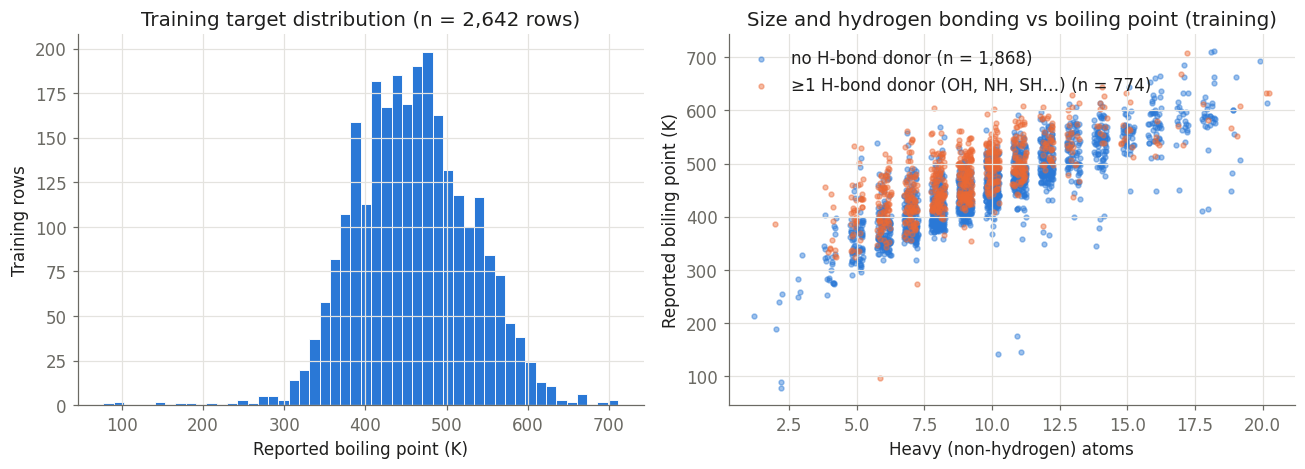

In [8]:
train_rows = audit.loc[audit['eligible'] & (audit['split'] == 'train')].copy()
train_rows['hbd'] = train_rows['canonical_smiles'].map(lambda s: Chem.rdMolDescriptors.CalcNumHBD(Chem.MolFromSmiles(s)))
print(train_rows['BP'].describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].hist(train_rows['BP'], bins=50, color=PALETTE[0], edgecolor='white', linewidth=0.6)
axes[0].set(xlabel='Reported boiling point (K)', ylabel='Training rows',
            title=f'Training target distribution (n = {len(train_rows):,} rows)')
for label, mask, color in [('no H-bond donor', train_rows['hbd'] == 0, PALETTE[0]),
                           ('≥1 H-bond donor (OH, NH, SH…)', train_rows['hbd'] > 0, PALETTE[1])]:
    axes[1].scatter(train_rows.loc[mask, 'heavy_atoms'] + np.random.default_rng(0).uniform(-0.25, 0.25, mask.sum()),
                    train_rows.loc[mask, 'BP'], s=10, alpha=0.45, color=color, label=f'{label} (n = {mask.sum():,})')
axes[1].set(xlabel='Heavy (non-hydrogen) atoms', ylabel='Reported boiling point (K)',
            title='Size and hydrogen bonding vs boiling point (training)')
axes[1].legend(loc='upper left')
fig.tight_layout()
save_fig(fig, 'step4_training_bp_overview.png')
plt.show()

### Inspect unusual training observations

Code Summary: Uses training rows only to list repeated structures whose records disagree, molecules far from a simple size trend, and molecules with five or more heavy atoms reported below 250 K. Nothing is removed here; unusual values are reasons to look, not proof of error.


In [9]:
# 1) Repeated records of the same structure in the training split: how much do they disagree?
rep = (train_rows.groupby('canonical_smiles')['BP'].agg(records='size', min_K='min', max_K='max')
       .query('records > 1').assign(spread_K=lambda d: d['max_K'] - d['min_K']).sort_values('spread_K'))
print(f'Training structures with repeated records: {len(rep)}; spread quantiles (K): '
      f'{rep["spread_K"].quantile([0.5, 0.75, 0.9]).round(1).to_dict()}')
display(rep.tail(6).round(2))

# 2) Off-trend molecules: robust training-only fit of BP against log(heavy atoms)
x, y = np.log(train_rows['heavy_atoms']), train_rows['BP']
slope, intercept = np.polyfit(x, y, 1)
resid = y - (intercept + slope * x)
robust_sigma = 1.4826 * np.median(np.abs(resid - np.median(resid)))
train_rows['trend_residual_K'] = resid
off = train_rows.loc[resid.abs() > 4 * robust_sigma, ['row_id', 'CAS', 'SMILES', 'heavy_atoms', 'BP', 'trend_residual_K']]
print(f'\nSize trend: BP ≈ {intercept:.0f} + {slope:.0f}·ln(heavy atoms); robust sigma {robust_sigma:.1f} K; '
      f'{len(off)} training rows beyond 4 sigma (shown: most negative and most positive)')
display(pd.concat([off.nsmallest(5, 'trend_residual_K'), off.nlargest(3, 'trend_residual_K')]).round(1))

# 3) Physically implausible low values for this chemistry
low = train_rows.loc[(train_rows['heavy_atoms'] >= LOW_BP_RULE['min_heavy_atoms']) & (train_rows['BP'] < LOW_BP_RULE['max_bp_K']),
                     ['row_id', 'CAS', 'SMILES', 'heavy_atoms', 'BP']]
print(f'Training rows with ≥{LOW_BP_RULE["min_heavy_atoms"]} heavy atoms below {LOW_BP_RULE["max_bp_K"]:.0f} K: {len(low)}')
display(low.assign(BP_plus_273=lambda d: d['BP'] + 273.15))

Training structures with repeated records: 65; spread quantiles (K): {0.5: 3.1, 0.75: 6.5, 0.9: 12.6}


,records,min_K,max_K,spread_K
canonical_smiles,,,,
CCC(C)C(=O)Cl,2,374.00,388.00,14.00
CC(C)(C)C=CC(C)(C)C,3,398.30,416.00,17.70
CC=C(C)C(C)=CC,3,377.15,407.15,30.00
C=C(C)C1CCC(C)CC1,3,441.70,516.15,74.45
CC(CO)CCO,3,364.15,466.15,102.00
CCC(C)CN,2,96.50,368.70,272.20



Size trend: BP ≈ 77 + 173·ln(heavy atoms); robust sigma 41.6 K; 9 training rows beyond 4 sigma (shown: most negative and most positive)


,row_id,CAS,SMILES,heavy_atoms,BP,trend_residual_K
1483,1483,4744-09-6,CCC(OC(C)C)OC(C)C,11,146.5,-345.0
1823,1823,32665-23-9,CC(C)CC(=O)OC(C)C,10,141.8,-333.2
3272,3272,109-19-3,CCCCOC(=O)CC(C)C,11,175.7,-315.8
1736,1736,36272-22-7,CCC(C)CN,6,96.5,-290.2
2565,2565,1731-86-8,CCCCCCCCCCC(=O)OC,14,344.2,-189.0
1893,1893,302-01-2,NN,2,386.6,189.8
1942,1942,288-88-0,C1=NC=NN1,5,533.2,178.0
1948,1948,288-32-4,C1=CN=CN1,5,530.2,175.0


Training rows with ≥5 heavy atoms below 250 K: 4


,row_id,CAS,SMILES,heavy_atoms,BP,BP_plus_273
1483,1483,4744-09-6,CCC(OC(C)C)OC(C)C,11,146.5,419.65
1736,1736,36272-22-7,CCC(C)CN,6,96.5,369.65
1823,1823,32665-23-9,CC(C)CC(=O)OC(C)C,10,141.8,414.95
3272,3272,109-19-3,CCCCOC(=O)CC(C)C,11,175.7,448.85


<h3 style="color:#B05E27;">What the training-only review suggests</h3>

- **Most repeated records agree closely** (a few kelvin), consistent with stereoisomers or repeat measurements of one compound. A handful disagree by tens to hundreds of kelvin, which no stereo effect explains.
- **Very low values for medium-sized molecules** stand out. Esters and acetals with ten or more heavy atoms cannot boil near 140–180 K; adding 273.15 gives typical values for such compounds, so these look like **Celsius values stored as kelvin**. The lowest-boiling closed-shell C/H/N/O/S/Cl molecules with five heavy atoms (for example neopentane, about 283 K) still boil far above 250 K, which motivates a chemistry-based plausibility rule.
- **Large positive residuals** are mostly strongly hydrogen-bonded or polyfunctional molecules: hard but genuine chemistry, not errors. They stay in the data.


<h2 style="color:#1D4E89;">Step 5: Data Carpentry</h2>

Data carpentry is the step where you decide how to improve the dataset before modeling. That can include fixing mistyped entries, removing or keeping duplicates, handling missing values, engineering new features, dropping weak features, and saving cleaner working files instead of overwriting the original data.

The cleaning policy below was motivated by the training-only review above and by chemistry knowledge, and it is applied **identically to every split**. The split itself was assigned to structures before this policy, so the policy cannot move molecules between splits. Full transparency: the assistant also saw a sorted preview of all boiling points when it first inspected the file, before the notebook existed; the rules below are deliberately chemistry-based thresholds rather than values tuned to particular rows.


### Decide and apply the cleaning policy

Code Summary: Records the cleaning decision with three reasoning paths, then applies it to all splits: ineligible rows are excluded, likely Celsius rows are excluded, agreeing repeated records are merged by median and conflicting repeats are excluded. Every row receives an action and reason in the audit.


In [10]:
record_decision(
    'a', 'Step 5', 'Cleaning and repeated-measurement policy',
    [('P1 Physical chemistry', 'Stereo-free SMILES merge E/Z isomers and diastereomers whose BPs differ by a few K up to ~15 K; their median is the best stereo-blind target. Larger spreads or sub-250 K values for ≥5 heavy atoms are physically implausible (likely unit errors) and could be corrected by +273.15.', 'merge ≤20 K by median; correct likely-Celsius rows'),
     ('P2 Statistics / ML', 'Unit errors of ~273 K are huge leverage points; a correction guesses the cause, while exclusion costs only a handful of rows from ~3,000. Medians are robust for merged groups; conflicting groups (midpoint between two disagreeing values is wrong for both) should be excluded.', 'merge ≤20 K by median; exclude conflicts and likely-Celsius rows'),
     ('P3 Skeptical reviewer', 'Never invent values: a suspected Celsius entry may be a different error. Exclude, audit and keep originals. Do not drop molecules because they are hard (strong H-bonders stay). Apply one rule to every split and at inference.', 'merge ≤20 K by median; exclude conflicts and likely-Celsius rows')],
    chosen=f'Exclude ineligible rows; exclude rows with ≥{LOW_BP_RULE["min_heavy_atoms"]} heavy atoms below '
           f'{LOW_BP_RULE["max_bp_K"]:.0f} K; merge repeated structures by median when their spread is ≤{DUPLICATE_TOLERANCE_K:.0f} K, '
           'otherwise exclude the structure as conflicting',
    agreement='3/3 on merging/conflicts; 2/3 on excluding (not correcting) likely-Celsius rows',
    resolution='Correcting a suspected unit error is a validity question, so the more conservative option (exclude and audit) wins.')

clean_audit = audit.copy()
clean_audit['action'] = np.where(clean_audit['eligible'], 'kept', 'excluded')
clean_audit['reason'] = clean_audit['eligibility_issue']
celsius = (clean_audit['eligible'] & (clean_audit['heavy_atoms'] >= LOW_BP_RULE['min_heavy_atoms'])
           & (clean_audit['BP'] < LOW_BP_RULE['max_bp_K']))
clean_audit.loc[celsius, ['action', 'reason']] = ['excluded', 'implausibly low for ≥5 heavy atoms (likely Celsius)']

alive = clean_audit['action'] == 'kept'
spread = clean_audit.loc[alive].groupby('canonical_smiles')['BP'].agg(lambda v: v.max() - v.min())
n_rec = clean_audit.loc[alive].groupby('canonical_smiles')['BP'].size()
conflict_ids = spread.index[spread > DUPLICATE_TOLERANCE_K]
merged_ids = n_rec.index[(n_rec > 1) & (spread <= DUPLICATE_TOLERANCE_K)]
is_conflict = alive & clean_audit['canonical_smiles'].isin(conflict_ids)
clean_audit.loc[is_conflict, ['action', 'reason']] = ['excluded', f'conflicting repeated records (spread > {DUPLICATE_TOLERANCE_K:.0f} K)']
is_merged = alive & clean_audit['canonical_smiles'].isin(merged_ids)
clean_audit.loc[is_merged, ['action', 'reason']] = ['merged', 'repeated structure; merged by median (spread ≤ 20 K)']

kept = clean_audit.loc[clean_audit['action'].isin(['kept', 'merged'])]
clean = (kept.groupby('canonical_smiles')
         .agg(bp_K=('BP', 'median'), n_records=('BP', 'size'), bp_spread_K=('BP', lambda v: v.max() - v.min()),
              split=('split', 'first'), source_smiles=('SMILES', 'first'),
              source_row_ids=('row_id', lambda v: ';'.join(map(str, v))),
              cas=('CAS', lambda v: ';'.join(map(str, v))) if 'CAS' in kept else ('row_id', 'size'))
         .reset_index())
assert clean['canonical_smiles'].is_unique and clean['split'].notna().all()
assert np.isfinite(clean['bp_K']).all()

summary = clean_audit.groupby(['action', 'reason']).size().rename('rows').reset_index()
display(summary)
print('Representative excluded rows after the target-based rules (all splits):')
display(clean_audit.loc[celsius | is_conflict, ['row_id', 'CAS', 'SMILES', 'BP', 'split', 'reason']]
        .sort_values('reason').head(12))
split_counts = clean['split'].value_counts().reindex(SPLIT_FRACTIONS)
print(f'Clean molecules: {len(clean):,} -> ' + ', '.join(f'{k} {v:,}' for k, v in split_counts.items()))

#### Decision (a) · Cleaning and repeated-measurement policy

| Path | Reasoning summary | Answer |
|---|---|---|
| P1 Physical chemistry | Stereo-free SMILES merge E/Z isomers and diastereomers whose BPs differ by a few K up to ~15 K; their median is the best stereo-blind target. Larger spreads or sub-250 K values for ≥5 heavy atoms are physically implausible (likely unit errors) and could be corrected by +273.15. | **merge ≤20 K by median; correct likely-Celsius rows** |
| P2 Statistics / ML | Unit errors of ~273 K are huge leverage points; a correction guesses the cause, while exclusion costs only a handful of rows from ~3,000. Medians are robust for merged groups; conflicting groups (midpoint between two disagreeing values is wrong for both) should be excluded. | **merge ≤20 K by median; exclude conflicts and likely-Celsius rows** |
| P3 Skeptical reviewer | Never invent values: a suspected Celsius entry may be a different error. Exclude, audit and keep originals. Do not drop molecules because they are hard (strong H-bonders stay). Apply one rule to every split and at inference. | **merge ≤20 K by median; exclude conflicts and likely-Celsius rows** |

**Chosen:** Exclude ineligible rows; exclude rows with ≥5 heavy atoms below 250 K; merge repeated structures by median when their spread is ≤20 K, otherwise exclude the structure as conflicting  
**Agreement:** 3/3 on merging/conflicts; 2/3 on excluding (not correcting) likely-Celsius rows  
**How disagreement was resolved:** Correcting a suspected unit error is a validity question, so the more conservative option (exclude and audit) wins.

,action,reason,rows
0,excluded,conflicting repeated records (spread > 20 K),9
1,excluded,empty or missing SMILES,229
2,excluded,implausibly low for ≥5 heavy atoms (likely Celsius),5
3,excluded,open-shell radical,1
4,excluded,stored MW 120.62 != SMILES MW 332.41 (identity mismatch),1
5,excluded,stored MW 124.22 != SMILES MW 175.19 (identity mismatch),1
6,excluded,stored MW 134.60 != SMILES MW 262.26 (identity mismatch),1
7,excluded,stored MW 146.23 != SMILES MW 333.43 (identity mismatch),1
8,excluded,stored MW 69.11 != SMILES MW 85.11 (identity mismatch),1
9,excluded,stored MW 84.15 != SMILES MW 78.11 (identity mismatch),1


Representative excluded rows after the target-based rules (all splits):


,row_id,CAS,SMILES,BP,split,reason
509,509,70423-38-0,CC(CCO)CO,364.15,train,conflicting repeated records (spread > 20 K)
1924,1924,2938-98-9,CC(CCO)CO,466.15,train,conflicting repeated records (spread > 20 K)
2147,2147,2417-88-1,CC=C(C)C(=CC)C,386.65,train,conflicting repeated records (spread > 20 K)
2210,2210,22644-28-6,CC(CCO)CO,367.15,train,conflicting repeated records (spread > 20 K)
2288,2288,21293-01-6,CC=C(C)C(=CC)C,377.15,train,conflicting repeated records (spread > 20 K)
2471,2471,1879-07-8,CC1CCC(CC1)C(=C)C,441.70,train,conflicting repeated records (spread > 20 K)
2511,2511,18265-39-9,CC=C(C)C(=CC)C,407.15,train,conflicting repeated records (spread > 20 K)
3139,3139,1124-27-2,CC1CCC(CC1)C(=C)C,446.00,train,conflicting repeated records (spread > 20 K)
3140,3140,1124-25-0,CC1CCC(CC1)C(=C)C,516.15,train,conflicting repeated records (spread > 20 K)
1483,1483,4744-09-6,CCC(OC(C)C)OC(C)C,146.50,train,implausibly low for ≥5 heavy atoms (likely Celsius)


Clean molecules: 3,189 -> train 2,551, validation 319, test 319


### Save the audit and clean working table

Code Summary: Writes the row-level cleaning audit and the clean table of unique molecules with their split, leaving the source file untouched. Original SMILES, row identifiers and CAS numbers are kept only for traceability.


In [11]:
AUDIT_PATH, CLEAN_PATH = OUT_DIR / 'cleaning_audit.csv', OUT_DIR / 'clean_molecules.csv'
clean_audit.drop(columns=['eligible']).to_csv(AUDIT_PATH, index=False)
clean.to_csv(CLEAN_PATH, index=False)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == DATA_SHA256, 'source file changed!'
print(f'Saved {AUDIT_PATH.relative_to(repo)} ({len(clean_audit):,} rows, one action per source row)')
print(f'Saved {CLEAN_PATH.relative_to(repo)} ({len(clean):,} unique molecules); source file unchanged.')

Saved 01_boiling_point/outputs/bp_one_shot_p2_1VC/cleaning_audit.csv (3,541 rows, one action per source row)
Saved 01_boiling_point/outputs/bp_one_shot_p2_1VC/clean_molecules.csv (3,189 unique molecules); source file unchanged.


### Choose the molecular representation

Code Summary: Records the representation decision with three reasoning paths. The paths agree on chemically motivated descriptors but split on adding fingerprints, so that question becomes a controlled validation experiment in Step 7.


In [12]:
record_decision(
    'c', 'Step 5', 'Molecular representation computed from SMILES',
    [('P1 Physical chemistry', 'BP reflects London dispersion (size, polarizability: MW, molar refractivity, surface area), H-bonding (OH/NH counts, acids, amides), dipoles (carbonyl, nitrile, nitro, TPSA) and shape (branching lowers contact area). Additive group contributions (Joback-style) motivate fragment counts too.', 'descriptors + Morgan count fingerprint'),
     ('P2 Statistics / ML', '~2,500 training molecules: ~35 dense descriptors suit every model family; a 1,024-bit count fingerprint adds local-environment detail but also variance and bit collisions, so its value must be measured, not assumed.', 'descriptors (test fingerprints as an ablation)'),
     ('P3 Skeptical reviewer', 'Recompute MW from SMILES and never use stored MW/CAS/3D blocks; keep features interpretable so failures can be explained; a fingerprint can memorise near-duplicates under a random split.', 'descriptors only')],
    chosen='Chemically grouped RDKit descriptors as the default; descriptors+Morgan counts and Morgan counts alone carried into Step 7',
    agreement='3/3 on descriptors; 1/3 for adding fingerprints',
    resolution='Empirical and cheap to test, so Step 7 runs a controlled representation ablation (same split, same models) and validation MAE decides.',
    outcome='pending Step 7 representation ablation')

desc_table = pd.DataFrame([(g, c) for g, cols in tk.DESCRIPTOR_GROUPS.items() for c in cols],
                          columns=['hypothesis group', 'descriptor'])
display(desc_table.groupby('hypothesis group')['descriptor'].apply(', '.join).to_frame())

#### Decision (c) · Molecular representation computed from SMILES

| Path | Reasoning summary | Answer |
|---|---|---|
| P1 Physical chemistry | BP reflects London dispersion (size, polarizability: MW, molar refractivity, surface area), H-bonding (OH/NH counts, acids, amides), dipoles (carbonyl, nitrile, nitro, TPSA) and shape (branching lowers contact area). Additive group contributions (Joback-style) motivate fragment counts too. | **descriptors + Morgan count fingerprint** |
| P2 Statistics / ML | ~2,500 training molecules: ~35 dense descriptors suit every model family; a 1,024-bit count fingerprint adds local-environment detail but also variance and bit collisions, so its value must be measured, not assumed. | **descriptors (test fingerprints as an ablation)** |
| P3 Skeptical reviewer | Recompute MW from SMILES and never use stored MW/CAS/3D blocks; keep features interpretable so failures can be explained; a fingerprint can memorise near-duplicates under a random split. | **descriptors only** |

**Chosen:** Chemically grouped RDKit descriptors as the default; descriptors+Morgan counts and Morgan counts alone carried into Step 7  
**Agreement:** 3/3 on descriptors; 1/3 for adding fingerprints  
**How disagreement was resolved:** Empirical and cheap to test, so Step 7 runs a controlled representation ablation (same split, same models) and validation MAE decides.

,descriptor
hypothesis group,
aromaticity,"aromatic_rings, frac_aromatic_atoms"
heteroatoms_halogens,"n_N, n_O, n_S, n_Cl"
hydrogen_bonding,"hbd, hba, n_OH_hydrogens, n_NH_hydrogens, n_carboxylic_a..."
polarity,"tpsa, logp, n_carbonyl, n_ester, n_ether_O, n_nitrile, n..."
shape_branching,"rot_bonds, kappa2, frac_csp3, n_methyl, n_quaternary_C, ..."
size_polarizability,"mol_wt, heavy_atoms, log_heavy_atoms, mol_mr, labute_asa..."


### Build SMILES-only feature matrices

Code Summary: Computes descriptors and Morgan count fingerprints from canonical SMILES for every clean molecule. No target is involved, so computing them for all rows leaks nothing; learned preprocessing is fitted later on training rows only. Asserts that no stored measurement is an input and saves the feature specification.


In [13]:
t0 = time.perf_counter()
features = tk.featurize(clean['canonical_smiles'], MORGAN_RADIUS, MORGAN_COUNT_BITS)
y_all = clean.set_index('canonical_smiles')['bp_K']
split_of = clean.set_index('canonical_smiles')['split']
assert features.index.equals(y_all.index), 'feature rows are not aligned with targets'
forbidden = {'BP', 'bp_K', 'MW', 'CAS', 'mol3D'}
assert not forbidden & set(features.columns), 'a stored measurement leaked into the inputs'
assert np.allclose(features['mol_wt'], clean['canonical_smiles'].map(tk.mol_weight)), 'MW must be recomputed from SMILES'
nonfinite = features.columns[~np.isfinite(features).all()].tolist()
print(f'Featurized {len(features):,} molecules x {features.shape[1]:,} columns in {time.perf_counter() - t0:.1f} s; '
      f'columns with missing values (median-imputed on training rows later): {nonfinite or "none"}')

FEATURE_SPEC = {
    'input': 'canonical SMILES (RDKit, stereo removed) only',
    'descriptor_groups': tk.DESCRIPTOR_GROUPS,
    'morgan_count_fingerprint': {'radius': MORGAN_RADIUS, 'bits': MORGAN_COUNT_BITS},
    'similarity_fingerprint': {'type': 'Morgan bit vector', 'radius': MORGAN_RADIUS, 'bits': SIMILARITY_BITS, 'metric': 'Tanimoto'},
    'feature_sets': {k: len(tk.feature_columns(k, MORGAN_COUNT_BITS)) for k in ('desc', 'fp', 'desc+fp')},
    'excluded_columns': sorted(forbidden), 'learned_preprocessing': 'median imputation and scaling fitted on training rows only',
}
(OUT_DIR / 'feature_spec.json').write_text(json.dumps(FEATURE_SPEC, indent=2))
display(features[tk.DESCRIPTOR_NAMES].head(3).round(2))

Featurized 3,189 molecules x 1,056 columns in 1.4 s; columns with missing values (median-imputed on training rows later): none


,mol_wt,heavy_atoms,log_heavy_atoms,mol_mr,labute_asa,n_C,hbd,hba,n_OH_hydrogens,n_NH_hydrogens,...,frac_csp3,n_methyl,n_quaternary_C,ring_count,aromatic_rings,frac_aromatic_atoms,n_N,n_O,n_S,n_Cl
C#C,26.04,2.0,0.69,9.89,14.10,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C#CC#CC,64.09,5.0,1.61,22.28,32.20,5.0,0.0,0.0,0.0,0.0,...,0.2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C#CC#N,51.05,4.0,1.39,14.45,24.86,3.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


### Which descriptors track boiling point? (training only)

Code Summary: Ranks each descriptor by its Spearman rank correlation with boiling point on training molecules only and plots the strongest fifteen, colored by hypothesis group. Correlations are associations that motivate experiments, not causes.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step5_descriptor_spearman_training.png


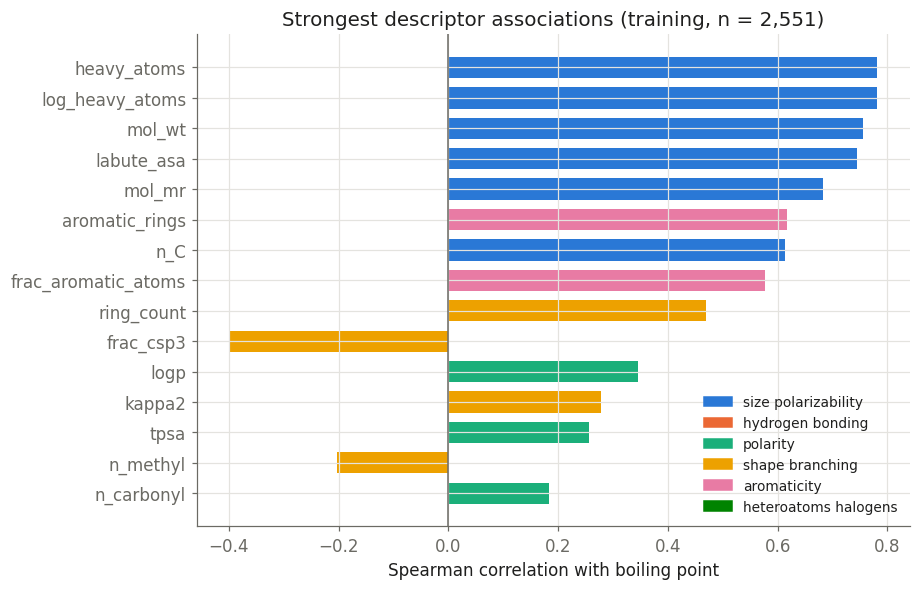

In [14]:
train_idx = split_of.index[split_of == 'train']
rho = features.loc[train_idx, tk.DESCRIPTOR_NAMES].corrwith(y_all.loc[train_idx], method='spearman').dropna()
group_of = {c: g for g, cols in tk.DESCRIPTOR_GROUPS.items() for c in cols}
group_color = dict(zip(tk.DESCRIPTOR_GROUPS, PALETTE))
top = rho.reindex(rho.abs().sort_values(ascending=True).index)[-15:]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top.index, top.values, color=[group_color[group_of[c]] for c in top.index], height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set(xlabel='Spearman correlation with boiling point', title=f'Strongest descriptor associations (training, n = {len(train_idx):,})')
handles = [plt.Rectangle((0, 0), 1, 1, color=group_color[g]) for g in tk.DESCRIPTOR_GROUPS]
ax.legend(handles, [g.replace('_', ' ') for g in tk.DESCRIPTOR_GROUPS], loc='lower right', fontsize=9)
fig.tight_layout()
save_fig(fig, 'step5_descriptor_spearman_training.png')
plt.show()

<h2 style="color:#1D4E89;">Step 6: Algorithm</h2>

The algorithm step is where you make choices about which models you want to use for your problem. You will also build baseline or starter model setups in this step for experimentation later.

Neighbouring workshop notebooks use graph neural networks and transformer embeddings. That is **not** a reason to use a neural network here: with about 2,500 training molecules and a compact descriptor set, classical models are fast, strong and easier to explain. The decision below makes the reasoning explicit.


### Choose the candidate algorithms

Code Summary: Records the algorithm decision with three reasoning paths. All paths include a linear model and gradient boosting; only one argues for a kernel model, so it is kept as an affordable candidate and the Step 7 comparison decides.


In [15]:
record_decision(
    'd', 'Step 6', 'Candidate regression algorithms',
    [('P1 Physical chemistry', 'Group-contribution methods (Joback) predict BP as a sum of fragment terms, so a regularised linear model is a physically meaningful reference; H-bonding and size effects interact nonlinearly (BP grows sub-linearly with size), which trees capture.', 'Ridge + gradient boosting'),
     ('P2 Statistics / ML', 'n ≈ 2,500 and p = 32-1,056: Ridge is low-variance, an RBF support-vector regressor gives smooth nonlinearity that works well at this size, and histogram gradient boosting handles interactions and missing values quickly.', 'Ridge + SVR + gradient boosting'),
     ('P3 Skeptical reviewer', 'No evidence a neural network is needed; prefer models whose training can be checkpointed and one that is interpretable. A nearest-neighbour model would mostly measure memorisation under a random split, so use it as an explanation tool, not a candidate.', 'Ridge + gradient boosting')],
    chosen='Training-median dummy baseline; Ridge; RBF support-vector regression (SVR); histogram gradient boosting (HGB)',
    agreement='3/3 Ridge, 3/3 gradient boosting, 1/3 SVR',
    resolution='Adding SVR is cheap and the disagreement is empirical, so all three run in the same Step 7 comparison. '
               'Nearest-neighbour similarity is used for explanations and applicability, not as a predictor.',
    outcome='pending Step 7 model-family comparison')

#### Decision (d) · Candidate regression algorithms

| Path | Reasoning summary | Answer |
|---|---|---|
| P1 Physical chemistry | Group-contribution methods (Joback) predict BP as a sum of fragment terms, so a regularised linear model is a physically meaningful reference; H-bonding and size effects interact nonlinearly (BP grows sub-linearly with size), which trees capture. | **Ridge + gradient boosting** |
| P2 Statistics / ML | n ≈ 2,500 and p = 32-1,056: Ridge is low-variance, an RBF support-vector regressor gives smooth nonlinearity that works well at this size, and histogram gradient boosting handles interactions and missing values quickly. | **Ridge + SVR + gradient boosting** |
| P3 Skeptical reviewer | No evidence a neural network is needed; prefer models whose training can be checkpointed and one that is interpretable. A nearest-neighbour model would mostly measure memorisation under a random split, so use it as an explanation tool, not a candidate. | **Ridge + gradient boosting** |

**Chosen:** Training-median dummy baseline; Ridge; RBF support-vector regression (SVR); histogram gradient boosting (HGB)  
**Agreement:** 3/3 Ridge, 3/3 gradient boosting, 1/3 SVR  
**How disagreement was resolved:** Adding SVR is cheap and the disagreement is empirical, so all three run in the same Step 7 comparison. Nearest-neighbour similarity is used for explanations and applicability, not as a predictor.

### Model builders and one shared fit interface

Code Summary: Defines one builder for every model family. Imputation and scaling sit inside each pipeline, so they are fitted on training rows only and applied identically at inference. Boosted models record training and validation error per iteration, then are refitted at the best iteration, which restores that checkpoint exactly.


In [16]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

DEFAULT_SETTINGS = {'median': {}, 'ridge': {'alpha': 10.0}, 'svr': {'C': 10.0, 'epsilon': 0.05},
                    'hgb': {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 10}}
PRIOR_ALPHA = 10.0   # fixed Ridge strength for the additive prior in the Step 7 enhancement


def build_model(family, settings=None):
    """Return (unfitted pipeline, settings). Every family takes a feature table and returns K."""
    base_family = family.replace('prior+', '')
    s = {**DEFAULT_SETTINGS[base_family], **(settings or {})}
    impute = ('impute', SimpleImputer(strategy='median'))
    if base_family == 'median':
        core = [('model', DummyRegressor(strategy='median'))]
    elif base_family == 'ridge':
        core = [impute, ('scale', StandardScaler()), ('model', Ridge(alpha=s['alpha']))]
    elif base_family == 'svr':
        svr = SVR(kernel='rbf', C=s['C'], epsilon=s['epsilon'], gamma='scale')
        core = [impute, ('scale', StandardScaler()), ('model', TransformedTargetRegressor(svr, transformer=StandardScaler()))]
    elif base_family == 'hgb':
        core = [impute, ('model', HistGradientBoostingRegressor(
            max_iter=s.get('max_iter', HGB_MAX_ITER), learning_rate=s['learning_rate'], max_leaf_nodes=s['max_leaf_nodes'],
            min_samples_leaf=s['min_samples_leaf'], early_stopping=False, random_state=SEED))]
    else:
        raise ValueError(family)
    if family.startswith('prior+'):
        prior = Pipeline([('scale', StandardScaler()), ('ridge', Ridge(alpha=PRIOR_ALPHA))])
        return Pipeline([impute, ('model', tk.PriorResidualRegressor(prior, Pipeline(core)))]), s
    return Pipeline(core), s


def staged_model(pipe):
    """Return (transformer prefix, boosted estimator) if the pipeline has a training history."""
    final = pipe[-1]
    if isinstance(final, HistGradientBoostingRegressor):
        return pipe[:-1], final
    if isinstance(final, tk.PriorResidualRegressor) and isinstance(final.residual[-1], HistGradientBoostingRegressor):
        return pipe[:-1], final
    return None, None


def fit_model(family, settings, cols, train_ids, val_ids):
    pipe, s = build_model(family, settings)
    Xtr, Xva = features.loc[train_ids, cols], features.loc[val_ids, cols]
    ytr, yva = y_all.loc[train_ids].to_numpy(), y_all.loc[val_ids].to_numpy()
    t0 = time.perf_counter()
    pipe.fit(Xtr, ytr)
    history = None
    prefix, booster = staged_model(pipe)
    if booster is not None:
        Ttr, Tva = prefix.transform(Xtr), prefix.transform(Xva)
        tr_curve = [mean_absolute_error(ytr, p) for p in booster.staged_predict(Ttr)]
        va_preds = list(booster.staged_predict(Tva))
        va_curve = [mean_absolute_error(yva, p) for p in va_preds]
        best = int(np.argmin(va_curve)) + 1
        key = [k for k in pipe.get_params() if k.endswith('max_iter')]
        assert len(key) == 1
        pipe.set_params(**{key[0]: best}).fit(Xtr, ytr)          # restore the selected checkpoint
        assert np.allclose(pipe.predict(Xva), va_preds[best - 1], atol=1e-6), 'checkpoint not restored'
        history = pd.DataFrame({'iteration': np.arange(1, len(va_curve) + 1), 'train_MAE_K': tr_curve,
                                'validation_MAE_K': va_curve})
        history['selected'] = history['iteration'] == best
        s = {**s, 'best_iteration': best, 'iterations_trained': len(va_curve)}
    return {'pipeline': pipe, 'settings': s, 'history': history, 'cols': list(cols),
            'train_ids': list(train_ids), 'val_ids': list(val_ids),
            'pred_train': pipe.predict(Xtr), 'pred_val': pipe.predict(Xva), 'runtime_s': time.perf_counter() - t0}

print('Model families:', ', '.join(DEFAULT_SETTINGS), '+ prior+<family> for the Step 7 enhancement')

Model families: median, ridge, svr, hgb + prior+<family> for the Step 7 enhancement


<h2 style="color:#1D4E89;">Step 7: Experiment</h2>

Design fair experiments comparing models, settings, or representations on the fixed training and validation assignments. Keep the final test set untouched until Step 10, after Step 9 optimization and model selection are complete.

Planned experiments (a bounded budget of at most 24, declared in the configuration cell):

1. **Baseline:** training-median dummy.
2. **Model families × representation** (resolves decisions c and d): Ridge, SVR and HGB on descriptors, Morgan counts, and both.
3. **Chemistry ablation:** remove the hydrogen-bonding descriptor group from the leading configuration.
4. **Bounded settings search:** the six pre-declared settings for the leading family.
5. **Creative enhancement:** an additive prior plus a learned residual, against an identical control.


### Load and verify the frozen splits

Code Summary: Reloads the split file saved in Step 4 and checks that it matches the clean table, that no structure appears in two splits, and that feature rows and targets are aligned. Test molecules are identified only so that every later step can refuse to touch them.


In [17]:
frozen = pd.read_csv(SPLIT_PATH)
assert frozen['canonical_smiles'].is_unique
check = clean[['canonical_smiles', 'split']].merge(frozen, on='canonical_smiles', suffixes=('', '_frozen'))
assert len(check) == len(clean) and (check['split'] == check['split_frozen']).all(), 'split drifted from Step 4'
TRAIN_IDS = clean.loc[clean['split'] == 'train', 'canonical_smiles'].tolist()
VAL_IDS = clean.loc[clean['split'] == 'validation', 'canonical_smiles'].tolist()
TEST_IDS = clean.loc[clean['split'] == 'test', 'canonical_smiles'].tolist()   # sealed until Step 10
assert not set(TRAIN_IDS) & set(VAL_IDS) and not set(TEST_IDS) & (set(TRAIN_IDS) | set(VAL_IDS))
assert features.index.equals(y_all.index) and set(features.index) == set(TRAIN_IDS) | set(VAL_IDS) | set(TEST_IDS)
print(f'Frozen splits verified: train {len(TRAIN_IDS):,} | validation {len(VAL_IDS):,} | test {len(TEST_IDS):,} (sealed)')
print('What this estimates: error on new molecules drawn from the same chemical distribution as the data set '
      '(interpolation). It does not guarantee accuracy for unfamiliar chemical families.')

Frozen splits verified: train 2,551 | validation 319 | test 319 (sealed)
What this estimates: error on new molecules drawn from the same chemical distribution as the data set (interpolation). It does not guarantee accuracy for unfamiliar chemical families.


### Experiment tracker

Code Summary: Creates numbered experiment folders, each with metadata, aligned training and validation predictions and a training history when one exists, plus a running summary table. A guard refuses to record any test-set molecule during experimentation.


In [18]:
EXPERIMENTS, RESULTS = [], {}
SUMMARY_PATH = EXP_DIR / 'experiment_summary.csv'


def log_experiment(name, hypothesis, family, feature_set, result):
    n = len(EXPERIMENTS) + 1
    assert n <= MAX_EXPERIMENTS, 'experiment budget exhausted'
    assert not set(TEST_IDS) & (set(result['train_ids']) | set(result['val_ids'])), 'test molecules may not be used here'
    eid = f'experiment_{n:03d}'
    folder = EXP_DIR / eid
    folder.mkdir(parents=True, exist_ok=True)
    preds = pd.concat([
        pd.DataFrame({'canonical_smiles': result['train_ids'], 'split': 'train', 'bp_K': y_all.loc[result['train_ids']].to_numpy(),
                      'pred_K': result['pred_train']}),
        pd.DataFrame({'canonical_smiles': result['val_ids'], 'split': 'validation', 'bp_K': y_all.loc[result['val_ids']].to_numpy(),
                      'pred_K': result['pred_val']})])
    preds['residual_K'] = preds['pred_K'] - preds['bp_K']
    preds.to_csv(folder / 'predictions.csv', index=False)
    if result['history'] is not None:
        result['history'].to_csv(folder / 'training_history.csv', index=False)
    mtr = metrics(y_all.loc[result['train_ids']], result['pred_train'])
    mva = metrics(y_all.loc[result['val_ids']], result['pred_val'])
    meta = {'experiment_id': eid, 'name': name, 'hypothesis': hypothesis, 'family': family, 'feature_set': feature_set,
            'n_features': len(result['cols']), 'settings': result['settings'], 'seed': SEED,
            'runtime_s': round(result['runtime_s'], 2), 'train': mtr, 'validation': mva, 'test': 'sealed (not computed)'}
    (folder / 'metadata.json').write_text(json.dumps(meta, indent=2, default=float))
    row = {'experiment_id': eid, 'name': name, 'family': family, 'feature_set': feature_set, 'n_features': len(result['cols']),
           'settings': json.dumps(result['settings'], default=float), 'train_MAE_K': mtr['MAE_K'], 'val_MAE_K': mva['MAE_K'],
           'val_RMSE_K': mva['RMSE_K'], 'val_R2': mva['R2'], 'gap_K': mva['MAE_K'] - mtr['MAE_K'],
           'runtime_s': result['runtime_s'], 'hypothesis': hypothesis}
    EXPERIMENTS.append(row)
    RESULTS[eid] = {**result, 'family': family, 'feature_set': feature_set, 'name': name}
    pd.DataFrame(EXPERIMENTS).to_csv(SUMMARY_PATH, index=False)
    print(f'{eid} | {name:<44} | train MAE {mtr["MAE_K"]:6.1f} K | val MAE {mva["MAE_K"]:6.1f} K | '
          f'val R² {mva["R2"]:.3f} | {result["runtime_s"]:5.1f} s')
    return eid


def run(name, hypothesis, family, feature_set, settings=None, drop_groups=()):
    cols = tk.feature_columns(feature_set, MORGAN_COUNT_BITS, drop_groups)
    return log_experiment(name, hypothesis, family, feature_set + (f' minus {"/".join(drop_groups)}' if drop_groups else ''),
                          fit_model(family, settings, cols, TRAIN_IDS, VAL_IDS))


summary_view = lambda: pd.DataFrame(EXPERIMENTS).sort_values('val_MAE_K')[
    ['experiment_id', 'name', 'family', 'feature_set', 'train_MAE_K', 'val_MAE_K', 'val_RMSE_K', 'val_R2', 'gap_K', 'runtime_s']].round(3)
print(f'Tracking experiments in {EXP_DIR.relative_to(repo)}')

Tracking experiments in 01_boiling_point/outputs/bp_one_shot_p2_1VC/experiments


### Training-median baseline

Code Summary: Fits the dummy baseline that predicts the training median for every molecule and reports its validation error. Every later model must beat this number clearly to be worth anything.


In [19]:
BASELINE_ID = run('Training-median baseline', 'A constant prediction sets the floor every model must beat.', 'median', 'desc')
BASELINE_VAL_MAE = EXPERIMENTS[-1]['val_MAE_K']
print(f'Training median = {np.median(y_all.loc[TRAIN_IDS]):.1f} K; baseline validation MAE = {BASELINE_VAL_MAE:.1f} K')

experiment_001 | Training-median baseline                     | train MAE   56.4 K | val MAE   54.5 K | val R² -0.012 |   0.0 s
Training median = 459.9 K; baseline validation MAE = 54.5 K


### Compare model families and representations

Code Summary: Fits Ridge, SVR and gradient boosting on descriptors, on Morgan count fingerprints, and on both, using identical splits. This one controlled grid resolves the open questions from the representation and algorithm decisions; every run is logged with its hypothesis.


In [20]:
HYP = {'desc': 'Chemically motivated descriptors capture size, H-bonding, polarity and shape.',
       'fp': 'Local atom environments alone (group-contribution-like counts) are enough.',
       'desc+fp': 'Fingerprints add local detail that descriptors miss.'}
for feature_set in ('desc', 'fp', 'desc+fp'):
    for family in ('ridge', 'svr', 'hgb'):
        run(f'{family.upper()} on {feature_set}', HYP[feature_set], family, feature_set)

grid = pd.DataFrame(EXPERIMENTS[1:]).pivot(index='family', columns='feature_set', values='val_MAE_K')[['desc', 'fp', 'desc+fp']]
display(grid.round(1).rename_axis('validation MAE (K)'))
LEADER = pd.DataFrame(EXPERIMENTS[1:]).sort_values('val_MAE_K').iloc[0]
print(f'Leading configuration so far: {LEADER["name"]} ({LEADER["val_MAE_K"]:.1f} K)')

experiment_002 | RIDGE on desc                                | train MAE   16.9 K | val MAE   16.8 K | val R² 0.877 |   0.0 s


experiment_003 | SVR on desc                                  | train MAE    7.0 K | val MAE   11.1 K | val R² 0.928 |   0.9 s


experiment_004 | HGB on desc                                  | train MAE    7.9 K | val MAE   13.1 K | val R² 0.919 |   5.5 s


experiment_005 | RIDGE on fp                                  | train MAE   13.0 K | val MAE   23.2 K | val R² 0.765 |   0.4 s


experiment_006 | SVR on fp                                    | train MAE    3.8 K | val MAE   26.6 K | val R² 0.686 |   5.5 s


experiment_007 | HGB on fp                                    | train MAE    5.9 K | val MAE   16.4 K | val R² 0.893 |  23.0 s


experiment_008 | RIDGE on desc+fp                             | train MAE   11.4 K | val MAE   19.3 K | val R² 0.856 |   0.4 s


experiment_009 | SVR on desc+fp                               | train MAE    3.7 K | val MAE   24.0 K | val R² 0.735 |   5.9 s


experiment_010 | HGB on desc+fp                               | train MAE    4.8 K | val MAE   12.1 K | val R² 0.928 |  18.8 s


feature_set,desc,fp,desc+fp
validation MAE (K),,,
hgb,13.1,16.4,12.1
ridge,16.8,23.2,19.3
svr,11.1,26.6,24.0


Leading configuration so far: SVR on desc (11.1 K)


### Hydrogen-bond descriptor ablation

Code Summary: Refits the leading configuration without the hydrogen-bonding descriptor group and compares validation error overall and for molecules with and without a hydrogen-bond donor, with counts. This tests one chemical hypothesis directly.


In [21]:
if 'desc' not in LEADER['feature_set']:
    print('Leader uses no descriptors; ablating the H-bond group on descriptors+fingerprints for the same family.')
abl_set = LEADER['feature_set'] if 'desc' in LEADER['feature_set'] else 'desc+fp'
ABLATION_ID = run(f'{LEADER["family"].upper()} on {abl_set}, no H-bond group',
                  'Explicit H-bond descriptors matter beyond what size, polarity and fingerprints already encode.',
                  LEADER['family'], abl_set, drop_groups=('hydrogen_bonding',))
ex = pd.DataFrame(EXPERIMENTS)
reference_id = ex.loc[(ex['family'] == LEADER['family']) & (ex['feature_set'] == abl_set), 'experiment_id'].iloc[0]
donor = features.loc[VAL_IDS, 'hbd'] > 0
rows = []
for eid in (reference_id, ABLATION_ID):
    err = np.abs(RESULTS[eid]['pred_val'] - y_all.loc[VAL_IDS].to_numpy())
    rows.append({'experiment': RESULTS[eid]['name'], 'all (n=%d)' % len(err): err.mean(),
                 'H-bond donor (n=%d)' % donor.sum(): err[donor.to_numpy()].mean(),
                 'no donor (n=%d)' % (~donor).sum(): err[~donor.to_numpy()].mean()})
display(pd.DataFrame(rows).set_index('experiment').round(1).rename_axis('validation MAE (K)'))

experiment_011 | SVR on desc, no H-bond group                 | train MAE    7.7 K | val MAE   11.3 K | val R² 0.917 |   0.9 s


,all (n=319),H-bond donor (n=98),no donor (n=221)
validation MAE (K),,,
SVR on desc,11.1,12.0,10.7
"SVR on desc, no H-bond group",11.3,11.9,11.0


### Bounded settings search for the leading family

Code Summary: Runs the six settings declared in the configuration cell for the leading family and feature set, logging each run. The grid was fixed before any model was fitted and is not extended after seeing results.


In [22]:
SEARCH_FAMILY, SEARCH_SET = LEADER['family'], LEADER['feature_set']
search_ids = []
for i, settings in enumerate(SETTINGS_GRIDS[SEARCH_FAMILY], start=1):
    label = ', '.join(f'{k}={v}' for k, v in settings.items())
    search_ids.append(run(f'{SEARCH_FAMILY.upper()} {SEARCH_SET} grid {i}: {label}',
                          'Settings search on the leading family; the split and features are held fixed.',
                          SEARCH_FAMILY, SEARCH_SET, settings))
search = pd.DataFrame(EXPERIMENTS).set_index('experiment_id').loc[search_ids]
BEST_SEARCH_ID = search['val_MAE_K'].idxmin()
print(f'Best setting: {RESULTS[BEST_SEARCH_ID]["name"]} -> {search.loc[BEST_SEARCH_ID, "val_MAE_K"]:.1f} K')

experiment_012 | SVR desc grid 1: C=3, epsilon=0.02           | train MAE    7.8 K | val MAE   11.5 K | val R² 0.920 |   0.8 s


experiment_013 | SVR desc grid 2: C=3, epsilon=0.1            | train MAE    9.1 K | val MAE   11.8 K | val R² 0.918 |   0.4 s


experiment_014 | SVR desc grid 3: C=10, epsilon=0.02          | train MAE    6.5 K | val MAE   11.1 K | val R² 0.929 |   1.2 s


experiment_015 | SVR desc grid 4: C=10, epsilon=0.1           | train MAE    8.1 K | val MAE   11.3 K | val R² 0.927 |   0.5 s


experiment_016 | SVR desc grid 5: C=30, epsilon=0.02          | train MAE    5.5 K | val MAE   11.6 K | val R² 0.924 |   2.3 s


experiment_017 | SVR desc grid 6: C=30, epsilon=0.1           | train MAE    7.5 K | val MAE   11.8 K | val R² 0.921 |   0.9 s
Best setting: SVR desc grid 3: C=10, epsilon=0.02 -> 11.1 K


### Validation error versus settings

Code Summary: Plots training and validation error for each setting in the bounded grid, so the learner can see where extra flexibility stops helping and starts to overfit.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step7_settings_search.png


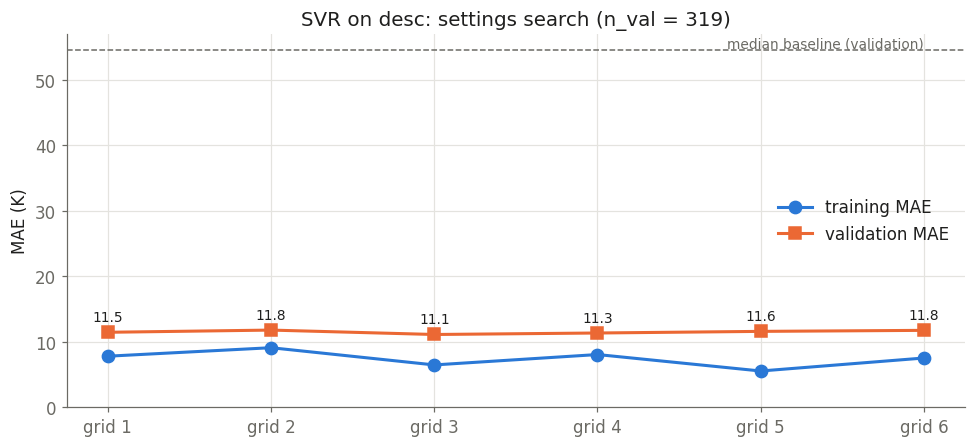

,name,train_MAE_K,val_MAE_K,gap_K,runtime_s
experiment_id,,,,,
experiment_012,"SVR desc grid 1: C=3, epsilon=0.02",7.80,11.46,3.65,0.77
experiment_013,"SVR desc grid 2: C=3, epsilon=0.1",9.10,11.79,2.69,0.39
experiment_014,"SVR desc grid 3: C=10, epsilon=0.02",6.47,11.12,4.65,1.17
experiment_015,"SVR desc grid 4: C=10, epsilon=0.1",8.06,11.35,3.29,0.55
experiment_016,"SVR desc grid 5: C=30, epsilon=0.02",5.54,11.60,6.05,2.31
experiment_017,"SVR desc grid 6: C=30, epsilon=0.1",7.53,11.75,4.22,0.91


In [23]:
fig, ax = plt.subplots(figsize=(9, 4.2))
xs = np.arange(len(search))
ax.plot(xs, search['train_MAE_K'], marker='o', color=PALETTE[0], linewidth=2, markersize=8, label='training MAE')
ax.plot(xs, search['val_MAE_K'], marker='s', color=PALETTE[1], linewidth=2, markersize=8, label='validation MAE')
ax.axhline(BASELINE_VAL_MAE, color=MUTED, linestyle='--', linewidth=1)
ax.text(len(xs) - 1, BASELINE_VAL_MAE, 'median baseline (validation)', ha='right', va='bottom', color=MUTED, fontsize=9)
ax.set_xticks(xs, [f'grid {i}' for i in range(1, len(xs) + 1)])
ax.set(ylabel='MAE (K)', ylim=(0, None), title=f'{SEARCH_FAMILY.upper()} on {SEARCH_SET}: settings search (n_val = {len(VAL_IDS)})')
ax.legend(loc='center right')
for x, (_, r) in zip(xs, search.iterrows()):
    ax.annotate(f'{r.val_MAE_K:.1f}', (x, r.val_MAE_K), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9)
fig.tight_layout()
save_fig(fig, 'step7_settings_search.png')
plt.show()
display(search[['name', 'train_MAE_K', 'val_MAE_K', 'gap_K', 'runtime_s']].round(2))

<h3 style="color:#B05E27;">Two ideas for making the predictions more useful</h3>

1. **Additive prior plus learned residual (implemented below).** Group-contribution methods such as Joback's predict boiling point as a sum of fragment terms. A Ridge model on the same features plays that role as a smooth, additive *prior*; the leading nonlinear model then learns only the *residual*. Hypothesis: the prior gives a smoother size trend at the edges of the data, where tree models are piecewise-constant, and the residual model can spend its capacity on interactions. Control: the identical tuned model without the prior.
2. **Nearest-neighbour explanations and an applicability signal (used as a diagnostic).** For each prediction, report the most similar training molecule, its similarity and its reported boiling point. This makes a prediction checkable by a chemist and flags unfamiliar chemistry. Step 8 tests whether validation error actually rises as similarity falls, which is what would justify the applicability label used by the prediction function.


### Enhancement: additive prior plus learned residual

Code Summary: Fits the tuned leading model on the residuals of a training-only Ridge prior and compares it with the identical model without the prior, overall and for the smallest and largest molecules, where extrapolation matters most.


In [24]:
control_id = BEST_SEARCH_ID
ctrl = RESULTS[control_id]
best_settings = {k: v for k, v in ctrl['settings'].items() if k not in ('best_iteration', 'iterations_trained')}
ENHANCE_ID = run(f'Prior + {SEARCH_FAMILY.upper()} residual on {SEARCH_SET}',
                 'A smooth additive Ridge prior plus a learned residual generalises better than the residual model alone.',
                 'prior+' + SEARCH_FAMILY, SEARCH_SET, best_settings)
ha = features.loc[VAL_IDS, 'heavy_atoms'].to_numpy()
q_lo, q_hi = np.quantile(features.loc[TRAIN_IDS, 'heavy_atoms'], [0.1, 0.9])
bands = {f'small (≤{q_lo:.0f} heavy atoms)': ha <= q_lo, 'middle': (ha > q_lo) & (ha < q_hi), f'large (≥{q_hi:.0f})': ha >= q_hi}
yv = y_all.loc[VAL_IDS].to_numpy()
table = pd.DataFrame({RESULTS[e]['name']: {f'{k} (n={m.sum()})': np.abs(RESULTS[e]['pred_val'] - yv)[m].mean()
                                           for k, m in {'all': np.ones_like(ha, bool), **bands}.items()}
                      for e in (control_id, ENHANCE_ID)}).T
display(table.round(1).rename_axis('validation MAE (K)'))

experiment_018 | Prior + SVR residual on desc                 | train MAE    7.2 K | val MAE   10.9 K | val R² 0.929 |   0.9 s


,all (n=319),small (≤6 heavy atoms) (n=33),middle (n=256),large (≥14) (n=30)
validation MAE (K),,,,
"SVR desc grid 3: C=10, epsilon=0.02",11.1,12.8,9.7,21.1
Prior + SVR residual on desc,10.9,14.7,9.7,17.1


### Validation comparison of all experiments

Code Summary: Draws one bar per experiment, sorted by validation error and colored by model family, with the median baseline as a reference line. Only validation data are used.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step7_validation_comparison.png


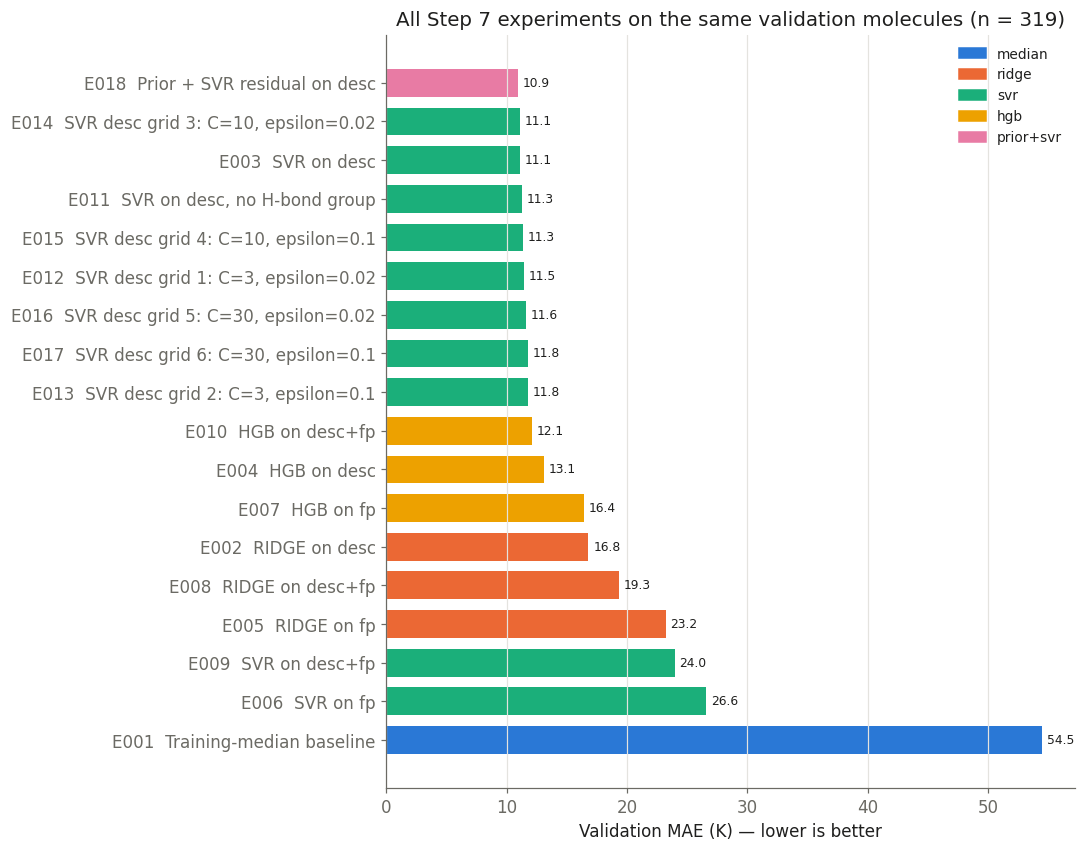

In [25]:
summ = pd.DataFrame(EXPERIMENTS).sort_values('val_MAE_K', ascending=False)
fam_order = ['median', 'ridge', 'svr', 'hgb', 'prior+ridge', 'prior+svr', 'prior+hgb']
fam_color = {f: PALETTE[i % len(PALETTE)] for i, f in enumerate([f for f in fam_order if f in set(summ['family'])])}
fig, ax = plt.subplots(figsize=(10, 0.36 * len(summ) + 1.4))
ax.barh(summ['experiment_id'].str.replace('experiment_', 'E') + '  ' + summ['name'].str.slice(0, 48), summ['val_MAE_K'],
        color=summ['family'].map(fam_color), height=0.72)
for yv_, v in enumerate(summ['val_MAE_K']):
    ax.text(v + 0.4, yv_, f'{v:.1f}', va='center', fontsize=8, color=INK)
ax.set(xlabel='Validation MAE (K) — lower is better', title=f'All Step 7 experiments on the same validation molecules (n = {len(VAL_IDS)})')
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_color.values()], fam_color.keys(), loc='upper right', fontsize=9)
ax.grid(axis='y', visible=False)
fig.tight_layout()
save_fig(fig, 'step7_validation_comparison.png')
plt.show()

<h3 style="color:#B05E27;">What Step 7 showed (validation only)</h3>

- **Every model beats the median baseline (54.5 K) by a wide margin**; the descriptor SVR leads at about 11.1 K.
- **Representation (decision c):** descriptors win for SVR (11.1 K) and Ridge (16.8 K). Adding 1,024 scaled fingerprint counts *hurts* them (24.0 and 19.3 K): the sparse bits dominate the RBF distance and dilute the 32 chemistry descriptors. Gradient boosting, which picks features split by split, gains slightly (13.1 → 12.1 K).
- **H-bond ablation:** removing the seven H-bond descriptors costs only 0.1–0.2 K. That reflects redundancy (TPSA, acceptor and O/N counts carry much of the same information), not evidence that hydrogen bonding is unimportant; Step 8 shuffles whole groups to check.
- **Settings search:** all six SVR settings fall between 11.1 and 11.8 K, so the model is not very sensitive in this range. Larger C lowers training error but not validation error.
- **Enhancement (prior + residual):** 10.9 vs 11.1 K overall, better on the largest molecules (21.1 → 17.1 K, n = 30) and worse on the smallest (12.8 → 14.7 K, n = 33). Step 8 tests whether that difference is larger than noise.


<h2 style="color:#1D4E89;">Step 8: Analysis</h2>

Analyze validation experiments and identify the most promising configuration and its limitations. Keep the test set sealed: Step 9 still allows optimization, so final test evaluation belongs in Step 10.

**A deliberate refinement of the template.** The original template evaluated finalists on the test set during analysis. Here the test set stays sealed until Step 10, because Step 9 still changes the model; looking at test results first would quietly turn the test set into a second validation set.

**Selection rule.** The declared criterion is validation MAE. Many differences above are a few tenths of a kelvin on 319 molecules, so before computing any resampling result this rule is added: *if a simpler configuration's paired-bootstrap 95 % interval for the MAE difference from the best includes zero, prefer the simpler one* (complexity order: median < Ridge < SVR = HGB < prior + model).


### Rank experiments and select the current best

Code Summary: Ranks every experiment by validation error with its training gap, then uses a paired bootstrap over validation molecules to ask whether the leaders differ by more than noise. Applies the simplicity rule stated above to name the current best configuration.


In [26]:
ranked = summary_view()
display(ranked.head(10).set_index('experiment_id'))
yv = y_all.loc[VAL_IDS].to_numpy()
abs_err = {e: np.abs(RESULTS[e]['pred_val'] - yv) for e in RESULTS}
TOP_ID = ranked.iloc[0]['experiment_id']
boot_rng = np.random.default_rng(SEED)
BOOT_IDX = boot_rng.integers(0, len(yv), size=(2000, len(yv)))


def paired_diff(a, b):
    """Mean and 95% interval of MAE(a) - MAE(b) over bootstrap resamples of validation molecules."""
    d = abs_err[a][BOOT_IDX].mean(1) - abs_err[b][BOOT_IDX].mean(1)
    return abs_err[a].mean() - abs_err[b].mean(), *np.percentile(d, [2.5, 97.5])


COMPLEXITY = {'median': 0, 'ridge': 1, 'svr': 2, 'hgb': 2}
complexity = lambda e: COMPLEXITY.get(RESULTS[e]['family'], 3)
rows = []
for e in ranked['experiment_id'].head(8):
    diff, lo, hi = paired_diff(e, TOP_ID)
    rows.append({'experiment_id': e, 'name': RESULTS[e]['name'], 'val_MAE_K': abs_err[e].mean(), 'diff_vs_top_K': diff,
                 'CI95_low': lo, 'CI95_high': hi, 'within_noise': lo <= 0 <= hi or e == TOP_ID, 'complexity': complexity(e)})
boot = pd.DataFrame(rows)
display(boot.round(2).set_index('experiment_id'))
eligible = boot[boot['within_noise']].sort_values(['complexity', 'val_MAE_K'])
CURRENT_BEST_ID = eligible.iloc[0]['experiment_id']
best = RESULTS[CURRENT_BEST_ID]
other_family = ranked[~ranked['family'].isin([best['family'], 'median', 'prior+' + best['family']])].iloc[0]['experiment_id']
print(f'Lowest validation MAE: {RESULTS[TOP_ID]["name"]} ({abs_err[TOP_ID].mean():.2f} K)')
print(f'Current best after the simplicity rule: {best["name"]} ({abs_err[CURRENT_BEST_ID].mean():.2f} K, '
      f'train-val gap {ranked.set_index("experiment_id").loc[CURRENT_BEST_ID, "gap_K"]:.1f} K)')
print(f'Best different family: {RESULTS[other_family]["name"]} ({abs_err[other_family].mean():.2f} K)')
d, lo, hi = paired_diff(ENHANCE_ID, control_id)
print(f'Enhancement vs control: {d:+.2f} K (95% CI {lo:+.2f} to {hi:+.2f}) -> '
      f'{"not distinguishable from noise" if lo <= 0 <= hi else "a real difference"}')

,name,family,feature_set,train_MAE_K,val_MAE_K,val_RMSE_K,val_R2,gap_K,runtime_s
experiment_id,,,,,,,,,
experiment_018,Prior + SVR residual on desc,prior+svr,desc,7.196,10.907,19.159,0.929,3.711,0.916
experiment_014,"SVR desc grid 3: C=10, epsilon=0.02",svr,desc,6.471,11.120,19.221,0.929,4.648,1.172
experiment_003,SVR on desc,svr,desc,7.025,11.125,19.369,0.928,4.100,0.875
experiment_011,"SVR on desc, no H-bond group",svr,desc minus hydrogen_bonding,7.721,11.260,20.716,0.917,3.538,0.904
experiment_015,"SVR desc grid 4: C=10, epsilon=0.1",svr,desc,8.058,11.347,19.394,0.927,3.289,0.548
experiment_012,"SVR desc grid 1: C=3, epsilon=0.02",svr,desc,7.805,11.457,20.417,0.920,3.652,0.774
experiment_016,"SVR desc grid 5: C=30, epsilon=0.02",svr,desc,5.544,11.596,19.902,0.924,6.052,2.308
experiment_017,"SVR desc grid 6: C=30, epsilon=0.1",svr,desc,7.529,11.752,20.186,0.921,4.223,0.909
experiment_013,"SVR desc grid 2: C=3, epsilon=0.1",svr,desc,9.101,11.793,20.682,0.918,2.692,0.391


,name,val_MAE_K,diff_vs_top_K,CI95_low,CI95_high,within_noise,complexity
experiment_id,,,,,,,
experiment_018,Prior + SVR residual on desc,10.91,0.00,0.00,0.00,True,3
experiment_014,"SVR desc grid 3: C=10, epsilon=0.02",11.12,0.21,-0.48,0.94,True,2
experiment_003,SVR on desc,11.12,0.22,-0.50,0.96,True,2
experiment_011,"SVR on desc, no H-bond group",11.26,0.35,-0.72,1.40,True,2
experiment_015,"SVR desc grid 4: C=10, epsilon=0.1",11.35,0.44,-0.37,1.23,True,2
experiment_012,"SVR desc grid 1: C=3, epsilon=0.02",11.46,0.55,-0.10,1.36,True,2
experiment_016,"SVR desc grid 5: C=30, epsilon=0.02",11.60,0.69,-0.15,1.57,True,2
experiment_017,"SVR desc grid 6: C=30, epsilon=0.1",11.75,0.84,-0.06,1.76,True,2


Lowest validation MAE: Prior + SVR residual on desc (10.91 K)
Current best after the simplicity rule: SVR desc grid 3: C=10, epsilon=0.02 (11.12 K, train-val gap 4.6 K)
Best different family: HGB on desc+fp (12.08 K)
Enhancement vs control: -0.21 K (95% CI -0.94 to +0.48) -> not distinguishable from noise


### Training history of the best boosting run

Code Summary: Plots training and validation error against boosting iteration for the best gradient-boosting experiment and marks the restored checkpoint. Non-iterative models such as Ridge and SVR have no training history, so none is invented for them.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step8_hgb_training_history.png


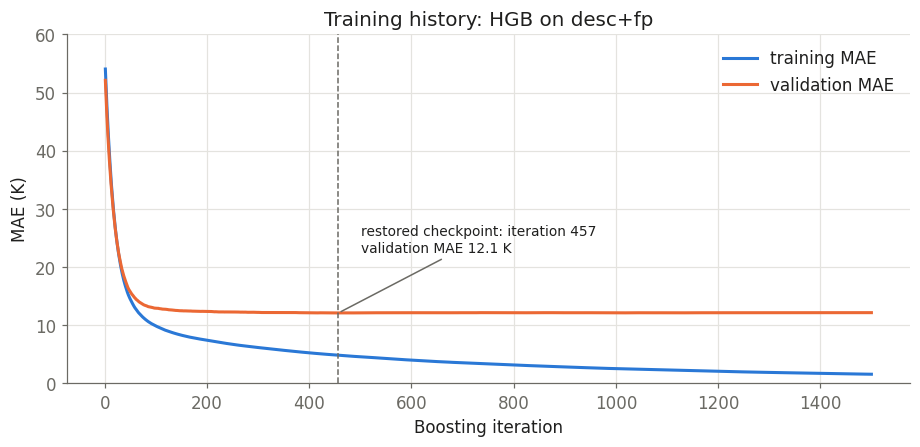

In [27]:
hgb_ids = [e for e in ranked['experiment_id'] if RESULTS[e]['history'] is not None]
hist_id = hgb_ids[0]
h = RESULTS[hist_id]['history']
sel = h.loc[h['selected']].iloc[0]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(h['iteration'], h['train_MAE_K'], color=PALETTE[0], linewidth=2, label='training MAE')
ax.plot(h['iteration'], h['validation_MAE_K'], color=PALETTE[1], linewidth=2, label='validation MAE')
ax.axvline(sel['iteration'], color=MUTED, linestyle='--', linewidth=1)
ax.annotate(f'restored checkpoint: iteration {int(sel.iteration)}\nvalidation MAE {sel.validation_MAE_K:.1f} K',
            (sel['iteration'], sel['validation_MAE_K']), xytext=(15, 40), textcoords='offset points', fontsize=9,
            arrowprops={'arrowstyle': '-', 'color': MUTED})
ax.set(xlabel='Boosting iteration', ylabel='MAE (K)', ylim=(0, 60), title=f'Training history: {RESULTS[hist_id]["name"]}')
ax.legend(loc='upper right')
fig.tight_layout()
save_fig(fig, 'step8_hgb_training_history.png')
plt.show()

### Validation parity and residual plots

Code Summary: Plots predicted against reported boiling point, and residuals against reported boiling point, for the current best model on validation molecules. The same plotting function is reused for the test set in Step 10.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step8_validation_parity_residuals.png


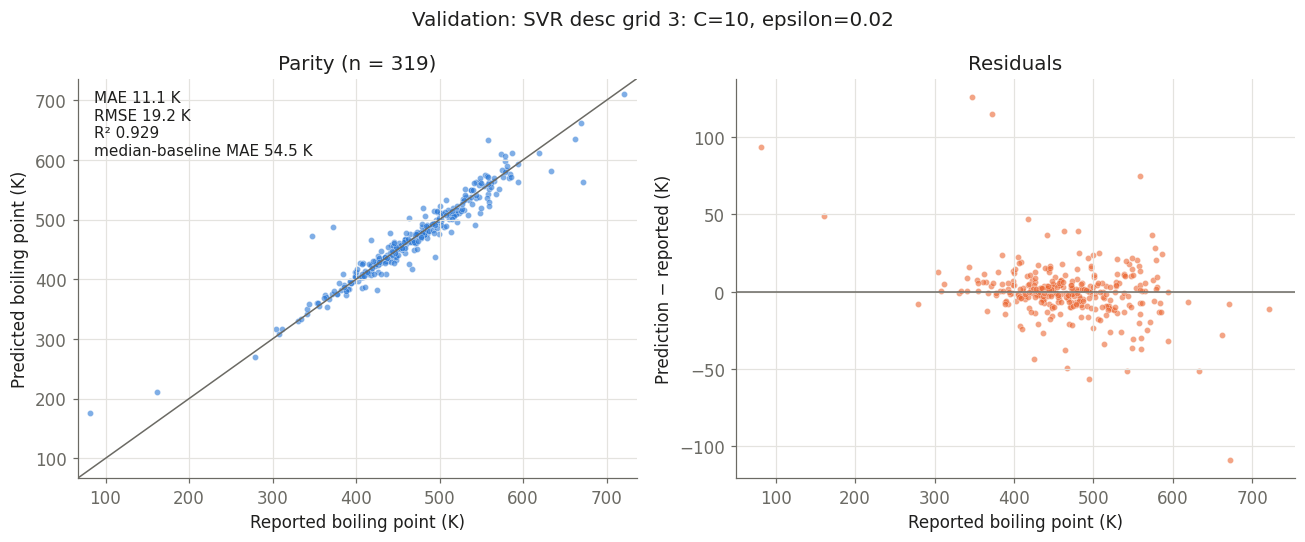

{'n': 319,
 'MAE_K': 11.119633691707412,
 'RMSE_K': 19.221337781145344,
 'R2': 0.9287671195041124}

In [28]:
def parity_residual_plot(y_true, y_pred, title, filename, baseline_mae):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    m = metrics(y_true, y_pred)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    lims = [min(y_true.min(), y_pred.min()) - 15, max(y_true.max(), y_pred.max()) + 15]
    axes[0].scatter(y_true, y_pred, s=16, alpha=0.6, color=PALETTE[0], edgecolor='white', linewidth=0.3)
    axes[0].plot(lims, lims, color=MUTED, linewidth=1)
    axes[0].set(xlim=lims, ylim=lims, xlabel='Reported boiling point (K)', ylabel='Predicted boiling point (K)',
                title=f'Parity (n = {m["n"]})')
    axes[0].text(0.03, 0.97, f'MAE {m["MAE_K"]:.1f} K\nRMSE {m["RMSE_K"]:.1f} K\nR² {m["R2"]:.3f}\n'
                 f'median-baseline MAE {baseline_mae:.1f} K', transform=axes[0].transAxes, va='top', fontsize=10)
    axes[1].scatter(y_true, y_pred - y_true, s=16, alpha=0.6, color=PALETTE[1], edgecolor='white', linewidth=0.3)
    axes[1].axhline(0, color=MUTED, linewidth=1)
    axes[1].set(xlabel='Reported boiling point (K)', ylabel='Prediction − reported (K)', title='Residuals')
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    save_fig(fig, filename)
    plt.show()
    return m


parity_residual_plot(yv, best['pred_val'], f'Validation: {best["name"]}', 'step8_validation_parity_residuals.png', BASELINE_VAL_MAE)

### Error by chemical subgroup and applicability band

Code Summary: Breaks validation error down by chemical subgroup, molecular size, similarity to the nearest training molecule and whether the ring scaffold is new, for the baseline and the current best model, with counts so small groups are not over-read.


In [29]:
from rdkit.Chem.Scaffolds import MurckoScaffold

train_fps = tk.similarity_fps(TRAIN_IDS, MORGAN_RADIUS, SIMILARITY_BITS)
val_sim, val_nn = tk.nearest_neighbours(tk.similarity_fps(VAL_IDS, MORGAN_RADIUS, SIMILARITY_BITS), train_fps)
scaffold = lambda s: MurckoScaffold.MurckoScaffoldSmiles(smiles=s)
train_scaffolds = {scaffold(s) for s in TRAIN_IDS}
fv = features.loc[VAL_IDS]
val_scaf = [scaffold(s) for s in VAL_IDS]
groups = {
    'all': np.ones(len(VAL_IDS), bool),
    'H-bond donor present': fv['hbd'].to_numpy() > 0,
    'no H-bond donor': fv['hbd'].to_numpy() == 0,
    'carboxylic acid': fv['n_carboxylic_acid'].to_numpy() > 0,
    'aromatic': fv['aromatic_rings'].to_numpy() > 0,
    'contains Cl': fv['n_Cl'].to_numpy() > 0,
    'contains N': fv['n_N'].to_numpy() > 0,
    'contains S': fv['n_S'].to_numpy() > 0,
    f'small (≤{q_lo:.0f} heavy atoms)': fv['heavy_atoms'].to_numpy() <= q_lo,
    f'large (≥{q_hi:.0f} heavy atoms)': fv['heavy_atoms'].to_numpy() >= q_hi,
    'acyclic': np.array([s == '' for s in val_scaf]),
    'ring scaffold new to training': np.array([s != '' and s not in train_scaffolds for s in val_scaf]),
    f'high similarity (≥{SIMILARITY_BANDS["high"]})': val_sim >= SIMILARITY_BANDS['high'],
    'medium similarity': (val_sim >= SIMILARITY_BANDS['low']) & (val_sim < SIMILARITY_BANDS['high']),
    f'low similarity (<{SIMILARITY_BANDS["low"]})': val_sim < SIMILARITY_BANDS['low'],
}
sub = pd.DataFrame({name: {'n': int(m.sum()), 'baseline MAE (K)': abs_err[BASELINE_ID][m].mean(),
                           'best model MAE (K)': abs_err[CURRENT_BEST_ID][m].mean(),
                           f'{RESULTS[other_family]["family"].upper()} MAE (K)': abs_err[other_family][m].mean()}
                    for name, m in groups.items() if m.sum() > 0}).T
sub['caution'] = np.where(sub['n'] < 20, 'n < 20: anecdotal', '')
display(sub.round(1))
rho_sim = pd.Series(val_sim).corr(pd.Series(abs_err[CURRENT_BEST_ID]), method='spearman')
print(f'Spearman correlation between similarity to training and absolute error: {rho_sim:+.2f} '
      f'(negative means less familiar molecules have larger errors)')

,n,baseline MAE (K),best model MAE (K),HGB MAE (K),caution
all,319.0,54.5,11.1,12.1,
H-bond donor present,98.0,46.8,11.8,10.6,
no H-bond donor,221.0,57.9,10.8,12.7,
carboxylic acid,5.0,67.8,14.8,12.5,n < 20: anecdotal
aromatic,123.0,67.1,13.5,12.6,
contains Cl,40.0,57.6,8.2,9.9,
contains N,74.0,58.2,15.0,13.2,
contains S,19.0,44.3,14.6,15.0,n < 20: anecdotal
small (≤6 heavy atoms),33.0,90.3,12.8,16.8,
large (≥14 heavy atoms),30.0,116.5,21.1,16.6,


Spearman correlation between similarity to training and absolute error: -0.13 (negative means less familiar molecules have larger errors)


### Representative successes and failures

Code Summary: Lists the best and worst predicted validation molecules with their most similar training molecule and its reported boiling point, so each error can be read chemically.


In [30]:
cases = pd.DataFrame({'smiles': VAL_IDS, 'reported_K': yv, 'predicted_K': best['pred_val'],
                      'error_K': best['pred_val'] - yv, 'nearest_train': [TRAIN_IDS[i] for i in val_nn],
                      'nearest_train_K': y_all.loc[[TRAIN_IDS[i] for i in val_nn]].to_numpy(), 'similarity': val_sim})
cases['abs_error_K'] = cases['error_K'].abs()
print('Best predicted validation molecules:')
display(cases.nsmallest(4, 'abs_error_K').drop(columns='abs_error_K').round(2))
print('Worst predicted validation molecules:')
display(cases.nlargest(6, 'abs_error_K').drop(columns='abs_error_K').round(2))

Best predicted validation molecules:


,smiles,reported_K,predicted_K,error_K,nearest_train,nearest_train_K,similarity
131,CCC1CCCc2ccccc21,512.55,512.53,-0.02,CCCCC1CCCc2ccccc21,546.21,0.70
125,CCC(O)(CC)C(C)C,432.15,432.20,0.05,CCCC(O)(CCC)C(C)C,462.15,0.58
117,CCC(C)CC(C)(C)CC,428.80,428.74,-0.06,CCC(C)(C)CC(Cl)Cl,449.00,0.50
120,CCC(C)OC(C)CC,394.00,393.90,-0.10,CCC(C)OC(C)C,373.20,0.73


Worst predicted validation molecules:


,smiles,reported_K,predicted_K,error_K,nearest_train,nearest_train_K,similarity
78,CC(CO)C(C)(C)O,347.10,473.26,126.16,CCC(C)C(C)(C)O,410.65,0.58
174,CCCCCOC(C)OCCCCC,372.45,487.44,114.99,CCCCOC(C)OCCCC,371.85,0.83
296,O=c1oc(=O)c2cc3c(=O)oc(=O)c3cc12,671.70,562.82,-108.88,Cc1cc(=O)cc(C)o1,522.20,0.33
309,[C-]#[O+],81.63,175.22,93.59,CC(C)C(C(C)C)C(C)C,430.19,0.11
221,CNc1ccccc1C(=O)c1ccccc1,558.20,632.93,74.73,COC(=O)c1ccccc1C(=O)c1ccccc1,625.00,0.58
256,Cc1cncn1C,494.20,437.70,-56.50,Cc1cn(C)cn1,472.20,0.31


### Which descriptor groups does the model rely on?

Code Summary: Shuffles each hypothesis group of descriptors together on validation molecules, five times, and measures how much validation error rises. Grouped shuffling avoids splitting credit between correlated descriptors. These are associations inside this model, not causes of boiling point.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step8_grouped_permutation_importance.png


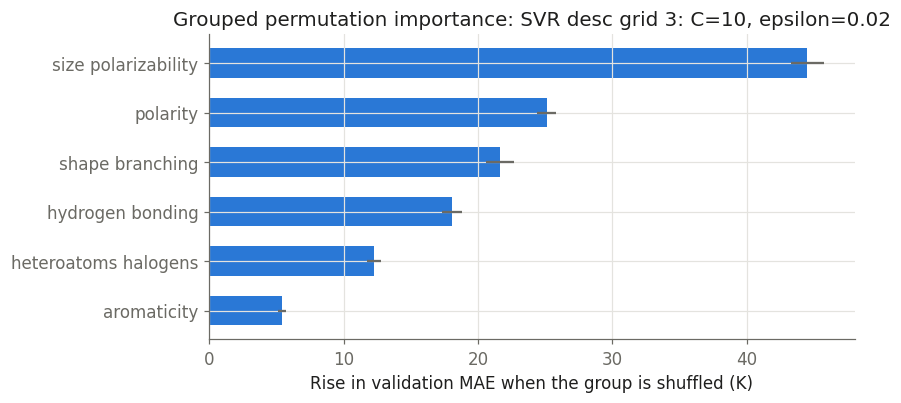

,mean_rise_K,sd_K
aromaticity,5.43,0.32
heteroatoms halogens,12.27,0.54
hydrogen bonding,18.05,0.74
shape branching,21.62,1.03
polarity,25.13,0.70
size polarizability,44.51,1.23


In [31]:
best_cols = best['cols']
Xv = features.loc[VAL_IDS, best_cols]
perm_rng = np.random.default_rng(SEED)
group_cols = {g: [c for c in cols if c in best_cols] for g, cols in tk.DESCRIPTOR_GROUPS.items()}
if any(c.startswith('morgan_') for c in best_cols):
    group_cols['Morgan fingerprint'] = [c for c in best_cols if c.startswith('morgan_')]
base_mae = abs_err[CURRENT_BEST_ID].mean()
imp = {}
for g, cols in group_cols.items():
    if not cols:
        continue
    rises = []
    for _ in range(5):
        Xp = Xv.copy()
        Xp[cols] = Xv[cols].to_numpy()[perm_rng.permutation(len(Xv))]
        rises.append(mean_absolute_error(yv, best['pipeline'].predict(Xp)) - base_mae)
    imp[g.replace('_', ' ')] = (np.mean(rises), np.std(rises))
imp = pd.DataFrame(imp, index=['mean_rise_K', 'sd_K']).T.sort_values('mean_rise_K')
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(imp.index, imp['mean_rise_K'], xerr=imp['sd_K'], color=PALETTE[0], height=0.6, error_kw={'ecolor': MUTED})
ax.set(xlabel='Rise in validation MAE when the group is shuffled (K)',
       title=f'Grouped permutation importance: {best["name"]}')
fig.tight_layout()
save_fig(fig, 'step8_grouped_permutation_importance.png')
plt.show()
display(imp.round(2))

<h3 style="color:#B05E27;">What the analysis shows</h3>

- **The leaders are tied within noise.** The prior + residual model is 0.21 K better, but its 95 % interval (−0.94 to +0.48 K) includes zero, so the simplicity rule selects the plain SVR (C = 10, ε = 0.02): 11.12 K validation MAE, 6.5 K training MAE, a moderate 4.6 K gap.
- **Weak spots:** large molecules (21.1 K, n = 30), nitrogen compounds (15.0 K, n = 74) and ring scaffolds absent from training (13.6 K, n = 24) versus 10.2 K for molecules with a highly similar training neighbour. The five low-similarity molecules average 40 K error, which is anecdotal but consistent with the skeptical path in decision (b). Per molecule, similarity is only a weak error signal (Spearman −0.13), so the applicability label is a coarse warning.
- **Several of the worst "errors" look like label problems:** a diol reported at 347 K (diols of this size boil well above 450 K) and an acetal at 372 K whose nearest training analogue is also unusually low. These may be reduced-pressure or mis-entered values. Carbon monoxide (81.6 K, similarity 0.11) is correctly flagged as unfamiliar.
- **Grouped importance** follows physical intuition: shuffling size/polarizability descriptors raises validation MAE by about 44 K, then polarity (25 K), shape (22 K) and hydrogen bonding (18 K). These are associations inside this model, not causal effects.


### Prepare, but do not run, the final test evaluation

Code Summary: Defines the function that will evaluate the frozen model and the baseline on the test set exactly once. It refuses to run unless the frozen-pipeline record from Step 9 exists, so the test set cannot be opened by accident during analysis.


In [32]:
FROZEN_RECORD = OUT_DIR / 'frozen_pipeline.json'
if FROZEN_RECORD.exists():
    FROZEN_RECORD.unlink()       # a stale record from an earlier run must not unlock the test set
TEST_OPENED = False


def evaluate_frozen_on_test(final_pipeline, final_cols, baseline_pipeline, baseline_cols):
    """Single, final test evaluation. Requires the Step 9 freeze record; may only run once."""
    global TEST_OPENED
    assert FROZEN_RECORD.exists(), 'Freeze the pipeline in Step 9 before opening the test set.'
    assert not TEST_OPENED, 'The test set has already been evaluated once.'
    TEST_OPENED = True
    rows, preds = [], {}
    for split, ids in (('train', TRAIN_IDS), ('validation', VAL_IDS), ('test', TEST_IDS)):
        y = y_all.loc[ids].to_numpy()
        for label, pipe, cols in (('median baseline', baseline_pipeline, baseline_cols),
                                  ('frozen model', final_pipeline, final_cols)):
            p = pipe.predict(features.loc[ids, cols])
            preds[(split, label)] = p
            rows.append({'split': split, 'model': label, **metrics(y, p)})
    return pd.DataFrame(rows), preds

print('Test evaluation function prepared; the test set is still sealed.')

Test evaluation function prepared; the test set is still sealed.


<h2 style="color:#1D4E89;">Step 9: Optimization</h2>

Optionally test one focused improvement using training/validation data only. Compare it fairly with the current baseline and keep the simpler or better-supported choice if it does not help. Freeze the selected pipeline and preprocessing before Step 10; do not search until a desired score appears.

Step 8 showed two things that motivate the improvement: the creative prior + residual model was not distinguishable from noise, and the two leading families fail on **different** molecules (the subgroup table above). The decision below picks one change, fixes its acceptance rule in advance, and then tests it once.


### Choose one focused improvement

Code Summary: Records the improvement decision with three reasoning paths built from the Step 8 numbers. All paths converge on averaging the two leading model families with fixed equal weights; the skeptical path adds a strict acceptance rule that is fixed before the comparison is run.


In [33]:
big = next(k for k in sub.index if k.startswith('large'))
OTHER_COL = f'{RESULTS[other_family]["family"].upper()} MAE (K)'
s_big, o_big = sub.loc[big, 'best model MAE (K)'], sub.loc[big, OTHER_COL]
s_hb, o_hb = sub.loc['H-bond donor present', 'best model MAE (K)'], sub.loc['H-bond donor present', OTHER_COL]
record_decision(
    'e', 'Step 9', 'One focused improvement after the Step 8 analysis',
    [('P1 Physical chemistry', f'SVR (RBF kernel) relaxes toward the mean far from training data, so large molecules suffer ({s_big:.1f} K vs {o_big:.1f} K for {RESULTS[other_family]["family"].upper()}, n = {int(sub.loc[big, "n"])}); the tree model handles H-bond donors better ({o_hb:.1f} vs {s_hb:.1f} K). Combining the two covers both chemistries.', 'average SVR and HGB'),
     ('P2 Statistics / ML', f'Two comparably accurate models ({abs_err[CURRENT_BEST_ID].mean():.1f} and {abs_err[other_family].mean():.1f} K) with different inductive biases: averaging reduces variance when errors are not perfectly correlated. Equal weights add no tunable parameter, so the only changed factor is "average or not".', 'average SVR and HGB (equal weights)'),
     ('P3 Skeptical reviewer', 'Validation has already been reused for ~18 comparisons, and the prior + residual gain vanished under resampling. Accept a change only if the paired-bootstrap 95% interval for the MAE difference lies entirely below zero; never tune ensemble weights on validation.', 'equal-weight average, accepted only if the interval excludes zero')],
    chosen=f'Equal-weight average of {RESULTS[CURRENT_BEST_ID]["name"]} and {RESULTS[other_family]["name"]}; accept only if '
           'the paired-bootstrap 95% interval of the MAE difference is entirely below 0, otherwise keep the single SVR',
    agreement='3/3 on the candidate; acceptance rule from P3',
    resolution='No disagreement on the candidate; the stricter acceptance rule from the skeptical path was adopted.')

#### Decision (e) · One focused improvement after the Step 8 analysis

| Path | Reasoning summary | Answer |
|---|---|---|
| P1 Physical chemistry | SVR (RBF kernel) relaxes toward the mean far from training data, so large molecules suffer (21.1 K vs 16.6 K for HGB, n = 30); the tree model handles H-bond donors better (10.6 vs 11.8 K). Combining the two covers both chemistries. | **average SVR and HGB** |
| P2 Statistics / ML | Two comparably accurate models (11.1 and 12.1 K) with different inductive biases: averaging reduces variance when errors are not perfectly correlated. Equal weights add no tunable parameter, so the only changed factor is "average or not". | **average SVR and HGB (equal weights)** |
| P3 Skeptical reviewer | Validation has already been reused for ~18 comparisons, and the prior + residual gain vanished under resampling. Accept a change only if the paired-bootstrap 95% interval for the MAE difference lies entirely below zero; never tune ensemble weights on validation. | **equal-weight average, accepted only if the interval excludes zero** |

**Chosen:** Equal-weight average of SVR desc grid 3: C=10, epsilon=0.02 and HGB on desc+fp; accept only if the paired-bootstrap 95% interval of the MAE difference is entirely below 0, otherwise keep the single SVR  
**Agreement:** 3/3 on the candidate; acceptance rule from P3  
**How disagreement was resolved:** No disagreement on the candidate; the stricter acceptance rule from the skeptical path was adopted.

### Run the improvement and decide

Code Summary: Averages the current best model and the best model of the other family, changing only that one factor, and applies the acceptance rule. Also checks whether the two members disagree more on molecules that turn out to have larger errors, a model-level analog of self-consistency.


In [34]:
members = [(RESULTS[e]['cols'], RESULTS[e]['pipeline']) for e in (CURRENT_BEST_ID, other_family)]
ensemble = tk.ColumnAverager(members)
all_cols = tk.feature_columns('desc+fp', MORGAN_COUNT_BITS)
need_cols = [c for c in all_cols if any(c in cols for cols, _ in members)]
t0 = time.perf_counter()
ens_result = {'pipeline': ensemble, 'settings': {'members': [CURRENT_BEST_ID, other_family], 'weights': [0.5, 0.5]},
              'history': None, 'cols': need_cols, 'train_ids': TRAIN_IDS, 'val_ids': VAL_IDS,
              'pred_train': ensemble.predict(features.loc[TRAIN_IDS]), 'pred_val': ensemble.predict(features.loc[VAL_IDS])}
ens_result['runtime_s'] = time.perf_counter() - t0
ENSEMBLE_ID = log_experiment(f'Average: {RESULTS[CURRENT_BEST_ID]["name"]} + {RESULTS[other_family]["name"]}',
                             'Averaging two families with different error patterns lowers validation MAE.',
                             'ensemble', 'desc (SVR) + desc+fp (HGB)', ens_result)
abs_err[ENSEMBLE_ID] = np.abs(ens_result['pred_val'] - yv)
diff, lo, hi = paired_diff(ENSEMBLE_ID, CURRENT_BEST_ID)
ACCEPTED = hi < 0
print(f'Ensemble minus current best: {diff:+.2f} K (95% CI {lo:+.2f} to {hi:+.2f}) -> '
      f'{"ACCEPTED" if ACCEPTED else "REJECTED: keep the simpler single model"}')
SC_LOG['e']['validation_outcome'] = (f'{"accepted" if ACCEPTED else "rejected"}: ensemble {abs_err[ENSEMBLE_ID].mean():.2f} K vs '
                                     f'{abs_err[CURRENT_BEST_ID].mean():.2f} K, difference CI [{lo:+.2f}, {hi:+.2f}] K')

member_val = ensemble.member_predictions(features.loc[VAL_IDS])
disagree = member_val.max(1) - member_val.min(1)
rho_dis = pd.Series(disagree).corr(pd.Series(abs_err[ENSEMBLE_ID]), method='spearman')
terc = pd.qcut(disagree, 3, labels=['lowest third', 'middle third', 'highest third'])
dis_table = pd.DataFrame({'member disagreement (K)': disagree, 'abs error (K)': abs_err[ENSEMBLE_ID], 'tercile': terc}) \
    .groupby('tercile', observed=True).agg(n=('abs error (K)', 'size'), median_disagreement_K=('member disagreement (K)', 'median'),
                                           ensemble_MAE_K=('abs error (K)', 'mean'))
display(dis_table.round(1))
print(f'Spearman(member disagreement, abs error) = {rho_dis:+.2f}. This is a diagnostic of model disagreement, '
      'not a calibrated probability or error bound.')

experiment_019 | Average: SVR desc grid 3: C=10, epsilon=0.02 + HGB on desc+fp | train MAE    5.2 K | val MAE   10.5 K | val R² 0.939 |   0.4 s
Ensemble minus current best: -0.65 K (95% CI -1.38 to +0.05) -> REJECTED: keep the simpler single model


,n,median_disagreement_K,ensemble_MAE_K
tercile,,,
lowest third,106,2.0,7.0
middle third,106,6.5,9.5
highest third,107,17.1,14.9


Spearman(member disagreement, abs error) = +0.23. This is a diagnostic of model disagreement, not a calibrated probability or error bound.


<h3 style="color:#B05E27;">Outcome of the improvement</h3>

The equal-weight average lowered validation MAE from 11.12 to 10.47 K, but the paired-bootstrap interval (−1.38 to +0.05 K) just includes zero, so the rule fixed in advance **rejects** it and the simpler single SVR is kept. The rule is there for this kind of case: after about 18 comparisons on the same 319 validation molecules, a 0.65 K gain is plausible but not established.

The model-disagreement diagnostic was informative: validation molecules where SVR and HGB disagree most have about twice the error of those where they agree (14.9 vs 7.0 K). That makes disagreement a promising applicability signal for future work. It is a diagnostic of model disagreement, not a calibrated error bar, and it is not deployed here because the ensemble was not adopted.


### Freeze the full pipeline before opening the test set

Code Summary: Builds the deployable predictor from the selected configuration, still trained on the training partition only, saves it with the toolkit module it needs, and writes a timestamped freeze record with the model checksum, policies and selection evidence. No test prediction exists yet.


In [35]:
FINAL_ID = ENSEMBLE_ID if ACCEPTED else CURRENT_BEST_ID
final_pipeline = RESULTS[FINAL_ID]['pipeline']
FINAL_COLS = RESULTS[FINAL_ID]['cols']
train_heavy = features.loc[TRAIN_IDS, 'heavy_atoms']
PREDICTOR_SETTINGS = {'morgan_radius': MORGAN_RADIUS, 'morgan_count_bits': MORGAN_COUNT_BITS,
                      'similarity_bits': SIMILARITY_BITS, 'similarity_bands': SIMILARITY_BANDS,
                      'heavy_atom_range': (int(train_heavy.min()), int(train_heavy.max())),
                      'supported_elements': tk.SUPPORTED_ELEMENTS, 'target_units': 'K'}
FINAL_PREDICTOR = tk.BoilingPointPredictor(final_pipeline, FINAL_COLS, TRAIN_IDS, y_all.loc[TRAIN_IDS], PREDICTOR_SETTINGS)
assert np.allclose(FINAL_PREDICTOR.predict(VAL_IDS)['bp_pred_K'], RESULTS[FINAL_ID]['pred_val']), 'predictor != experiment'
MODEL_PATH = MODEL_DIR / 'bp_predictor.joblib'
joblib.dump(FINAL_PREDICTOR, MODEL_PATH, compress=3)
MODEL_SHA256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
freeze = {
    'frozen_at': time.strftime('%Y-%m-%dT%H:%M:%S%z'), 'final_experiment': FINAL_ID, 'final_name': RESULTS[FINAL_ID]['name'],
    'members': RESULTS[FINAL_ID]['settings'].get('members', [FINAL_ID]),
    'member_settings': {e: RESULTS[e]['settings'] for e in RESULTS[FINAL_ID]['settings'].get('members', [FINAL_ID])},
    'trained_on': 'training partition only', 'n_features': len(FINAL_COLS),
    'validation_MAE_K': float(abs_err[FINAL_ID].mean()), 'selection_rule': 'validation MAE + paired-bootstrap simplicity rule',
    'cleaning_policy': SC_LOG['a']['chosen'], 'applicability_policy': PREDICTOR_SETTINGS,
    'model_file': MODEL_PATH.relative_to(repo).as_posix(), 'model_sha256': MODEL_SHA256,
    'test_set': 'sealed at freeze time'}
FROZEN_RECORD.write_text(json.dumps(freeze, indent=2, default=str))
print(f'Frozen: {freeze["final_name"]} | validation MAE {freeze["validation_MAE_K"]:.2f} K | '
      f'model {MODEL_PATH.stat().st_size / 1e6:.2f} MB | sha256 {MODEL_SHA256[:16]}…')

Frozen: SVR desc grid 3: C=10, epsilon=0.02 | validation MAE 11.12 K | model 0.15 MB | sha256 cee82dff578134fe…


<h2 style="color:#1D4E89;">Step 10: Solved?</h2>

Evaluate the frozen model and a training-median baseline once on the held-out test set. Report split counts, MAE/RMSE in kelvin, R-squared, and a parity plot; do not use test results for further tuning. Save and reload the inference pipeline and demonstrate an editable SMILES prediction. Did you meet the goal from Step 1? Report actual findings and limitations honestly, including if the model failed to improve on the baseline.

The numbers below are the **final generalization estimate for this random molecule-level split**. Nothing after this point changes the model.


### Open the test set once and evaluate

Code Summary: Confirms that the saved model file matches the freeze record, loads it, and evaluates the frozen model and the median baseline once on every split. Reports counts, MAE, RMSE and R-squared and saves the metrics and aligned test predictions.


In [36]:
assert hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest() == json.loads(FROZEN_RECORD.read_text())['model_sha256']
frozen_predictor = joblib.load(MODEL_PATH)
final_table, final_preds = evaluate_frozen_on_test(frozen_predictor.pipeline, frozen_predictor.feature_cols,
                                                   RESULTS[BASELINE_ID]['pipeline'], RESULTS[BASELINE_ID]['cols'])
assert np.allclose(final_preds[('validation', 'frozen model')], RESULTS[FINAL_ID]['pred_val'])
final_table.to_csv(OUT_DIR / 'final_metrics.csv', index=False)
view = final_table.pivot(index='split', columns='model', values=['n', 'MAE_K', 'RMSE_K', 'R2']).reindex(['train', 'validation', 'test'])
display(view.round(3))

yt = y_all.loc[TEST_IDS].to_numpy()
test_sim, test_nn = tk.nearest_neighbours(tk.similarity_fps(TEST_IDS, MORGAN_RADIUS, SIMILARITY_BITS), train_fps)
test_out = pd.DataFrame({'canonical_smiles': TEST_IDS, 'reported_K': yt,
                         'predicted_K': final_preds[('test', 'frozen model')], 'baseline_K': final_preds[('test', 'median baseline')],
                         'max_train_similarity': test_sim,
                         'applicability': [tk.similarity_band(v, SIMILARITY_BANDS) for v in test_sim],
                         'nearest_train': [TRAIN_IDS[i] for i in test_nn]})
test_out['error_K'] = test_out['predicted_K'] - test_out['reported_K']
assert len(test_out) == len(TEST_IDS) and np.isfinite(test_out['predicted_K']).all()
test_out.to_csv(OUT_DIR / 'test_predictions.csv', index=False)
T = final_table.set_index(['split', 'model'])
TEST_MAE, BASE_TEST_MAE = T.loc[('test', 'frozen model'), 'MAE_K'], T.loc[('test', 'median baseline'), 'MAE_K']
REDUCTION = 1 - TEST_MAE / BASE_TEST_MAE
print(f'Test MAE {TEST_MAE:.2f} K vs baseline {BASE_TEST_MAE:.2f} K -> {REDUCTION:.1%} reduction '
      f'(criterion: ≥ {SUCCESS_MAE_REDUCTION:.0%}).')

n                        MAE_K                       RMSE_K                           R2                
model      frozen model median baseline frozen model median baseline frozen model median baseline frozen model median baseline
split                                                                                                                         
train            2551.0          2551.0        6.471          56.387       15.934          70.440        0.949          -0.000
validation        319.0           319.0       11.120          54.491       19.221          72.435        0.929          -0.012
test              319.0           319.0       10.668          55.191       20.121          68.235        0.913          -0.000

Test MAE 10.67 K vs baseline 55.19 K -> 80.7% reduction (criterion: ≥ 50%).


### Test parity and residual plots

Code Summary: Plots the frozen model's test predictions against reported boiling points, and the residuals, with the same function used for validation.


Saved figure: 01_boiling_point/outputs/bp_one_shot_p2_1VC/figures/step10_test_parity_residuals.png


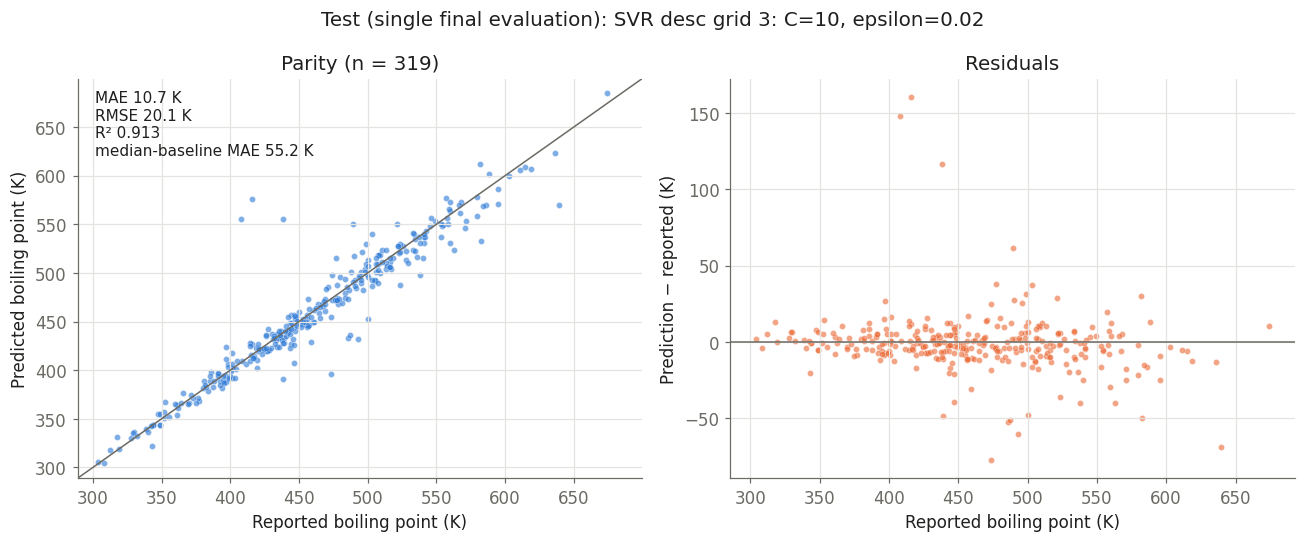

{'n': 319,
 'MAE_K': 10.667606094547388,
 'RMSE_K': 20.120584274691026,
 'R2': 0.9130453128081979}

In [37]:
parity_residual_plot(yt, test_out['predicted_K'], f'Test (single final evaluation): {RESULTS[FINAL_ID]["name"]}',
                     'step10_test_parity_residuals.png', BASE_TEST_MAE)

### Representative test errors and applicability check

Code Summary: Lists the best and worst test predictions with their nearest training molecule, and reports test error by similarity band with counts. Reported for understanding only; nothing is tuned after this.


In [38]:
test_out['abs_error_K'] = test_out['error_K'].abs()
cols_show = ['canonical_smiles', 'reported_K', 'predicted_K', 'error_K', 'nearest_train', 'max_train_similarity']
print('Best test predictions:')
display(test_out.nsmallest(3, 'abs_error_K')[cols_show].round(2))
print('Worst test predictions:')
display(test_out.nlargest(5, 'abs_error_K')[cols_show].round(2))
band_table = test_out.groupby('applicability').agg(n=('abs_error_K', 'size'), MAE_K=('abs_error_K', 'mean'),
                                                   median_abs_error_K=('abs_error_K', 'median')).reindex(['high', 'medium', 'low'])
display(band_table.round(1).rename_axis('similarity band (test)'))

Best test predictions:


,canonical_smiles,reported_K,predicted_K,error_K,nearest_train,max_train_similarity
31,C=CCOC,319.2,319.20,-0.00,C=CCOCC=C,0.50
298,O=Cc1ccccc1Cl,485.1,485.28,0.18,O=Cc1ccccc1O,0.50
215,CN(C)CCCCN(C)C,439.7,439.97,0.27,CN(C)CCCCCCN(C)C,0.91


Worst test predictions:


,canonical_smiles,reported_K,predicted_K,error_K,nearest_train,max_train_similarity
171,CCCCCCCCCCCCCC(Cl)Cl,415.65,576.10,160.45,CCCCCCC(C)Cl,0.65
181,CCCCOC(=O)CCC(=O)OCCCC,408.00,555.66,147.66,CCCCOC(=O)CCCCC(=O)OCCCC,0.86
168,CCCCCCCCCCC(=O)O,438.15,554.93,116.78,CCCCCCCCCCCC(=O)O,1.00
228,COC=CC(C)=O,473.20,395.97,-77.23,COC(=O)C=CC(=O)OC,0.38
317,c1ccc2c(c1)Sc1ccccc1S2,639.20,570.18,-69.02,c1ccc2c(c1)Nc1ccccc1S2,0.56


,n,MAE_K,median_abs_error_K
similarity band (test),,,
high,247,10.4,5.7
medium,68,10.7,6.5
low,4,26.1,26.0


### Was the goal met?

Code Summary: Records the final interpretation with three reasoning paths that use the actual test numbers, including a paired bootstrap interval for the error reduction, and states the answer to the Step 1 criterion.


In [39]:
b_idx = np.random.default_rng(SEED).integers(0, len(yt), size=(2000, len(yt)))
abs_m, abs_b = test_out['abs_error_K'].to_numpy(), np.abs(test_out['baseline_K'] - yt).to_numpy()
red_ci = np.percentile(1 - abs_m[b_idx].mean(1) / abs_b[b_idx].mean(1), [2.5, 97.5])
MET = REDUCTION >= SUCCESS_MAE_REDUCTION
p1 = 'met' if MET else 'not met'
p2 = 'met' if red_ci[0] >= SUCCESS_MAE_REDUCTION else ('met on the point estimate only' if MET else 'not met')
p3 = 'met, for this random split only' if MET else 'not met'
answers = [p1, p2, p3]
n_agree = sum(a.startswith('met') for a in answers) if MET else sum(a == 'not met' for a in answers)
rep_med, rep_p90 = rep['spread_K'].quantile(0.5), rep['spread_K'].quantile(0.9)
record_decision(
    'f', 'Step 10', f'Was the Step 1 criterion (≥{SUCCESS_MAE_REDUCTION:.0%} lower test MAE than the median baseline) met?',
    [('P1 Physical chemistry', f'Test MAE {TEST_MAE:.1f} K against a target spread of ~{y_all.std():.0f} K. Repeated records of one structure differ by a median {rep_med:.1f} K (90th percentile {rep_p90:.1f} K), so a few kelvin of the error is irreducible label noise; the model captures the size, polarity and H-bonding trends.', p1),
     ('P2 Statistics / ML', f'Reduction {REDUCTION:.1%} (paired bootstrap 95% CI {red_ci[0]:.1%} to {red_ci[1]:.1%}) versus the {SUCCESS_MAE_REDUCTION:.0%} bar; validation and test MAE agree ({abs_err[FINAL_ID].mean():.1f} vs {TEST_MAE:.1f} K), so selection did not overfit validation badly.', p2),
     ('P3 Skeptical reviewer', 'The split is random, so this measures interpolation within NIST-like chemistry; RMSE is dominated by a few large misses, some of which look like label problems; low-similarity molecules are rare in the test set and remain unvalidated.', p3)],
    chosen=('Criterion met' if MET else 'Criterion not met') + ' for this split; not evidence of accuracy on unfamiliar chemical families',
    agreement=f'{n_agree}/3',
    resolution='Paths agree on the verdict; the skeptical path limits the scope of the claim, which is adopted.',
    outcome=f'test MAE {TEST_MAE:.2f} K vs baseline {BASE_TEST_MAE:.2f} K ({REDUCTION:.1%} reduction)')

#### Decision (f) · Was the Step 1 criterion (≥50% lower test MAE than the median baseline) met?

| Path | Reasoning summary | Answer |
|---|---|---|
| P1 Physical chemistry | Test MAE 10.7 K against a target spread of ~70 K. Repeated records of one structure differ by a median 3.1 K (90th percentile 12.6 K), so a few kelvin of the error is irreducible label noise; the model captures the size, polarity and H-bonding trends. | **met** |
| P2 Statistics / ML | Reduction 80.7% (paired bootstrap 95% CI 76.7% to 84.1%) versus the 50% bar; validation and test MAE agree (11.1 vs 10.7 K), so selection did not overfit validation badly. | **met** |
| P3 Skeptical reviewer | The split is random, so this measures interpolation within NIST-like chemistry; RMSE is dominated by a few large misses, some of which look like label problems; low-similarity molecules are rare in the test set and remain unvalidated. | **met, for this random split only** |

**Chosen:** Criterion met for this split; not evidence of accuracy on unfamiliar chemical families  
**Agreement:** 3/3  
**How disagreement was resolved:** Paths agree on the verdict; the skeptical path limits the scope of the claim, which is adopted.

### Reflect on the self-consistency log

Code Summary: Fills in, for each earlier decision, what the validation evidence later showed, then prints the log with agreement levels and saves it. Low-agreement decisions are the interesting ones: did evidence confirm or overturn the majority?


In [40]:
G = grid  # family x representation validation MAE table from Step 7
SC_LOG['a']['validation_outcome'] = ('validity decision, not tuned on scores; every exclusion is listed in cleaning_audit.csv '
                                     f'({int((clean_audit["action"] == "excluded").sum())} rows excluded)')
SC_LOG['b']['validation_outcome'] = (f'diagnostic only: validation MAE {sub.loc["ring scaffold new to training", "best model MAE (K)"]:.1f} K '
                                     f'for new ring scaffolds (n = {int(sub.loc["ring scaffold new to training", "n"])}) vs '
                                     f'{sub.loc["all", "best model MAE (K)"]:.1f} K overall; the skeptic\'s concern is real but modest here')
SC_LOG['c']['validation_outcome'] = (f'majority confirmed for the winning family: SVR desc {G.loc["svr", "desc"]:.1f} K vs desc+fp '
                                     f'{G.loc["svr", "desc+fp"]:.1f} K; the minority (add fingerprints) helped only HGB '
                                     f'({G.loc["hgb", "desc"]:.1f} -> {G.loc["hgb", "desc+fp"]:.1f} K)')
SC_LOG['d']['validation_outcome'] = (f'the 1/3 minority candidate (SVR) was the best single family ({G.loc["svr", "desc"]:.1f} K vs '
                                     f'HGB {G.loc["hgb", "desc+fp"]:.1f} K, Ridge {G["desc"]["ridge"]:.1f} K): keeping a cheap '
                                     'minority option alive and testing it paid off')
log = pd.DataFrame(SC_LOG.values())
log.to_csv(SC_LOG_PATH, index=False)
display(log[['decision', 'step', 'question', 'chosen', 'agreement', 'validation_outcome']].set_index('decision'))
print(f'Saved {SC_LOG_PATH.relative_to(repo)}')

,step,question,chosen,agreement,validation_outcome
decision,,,,,
b,Step 5 (made in Step 4),Train/validation/test split design,"Random 80/10/10 split of unique canonical structures, se...",2/3,diagnostic only: validation MAE 13.6 K for new ring scaf...
a,Step 5,Cleaning and repeated-measurement policy,Exclude ineligible rows; exclude rows with ≥5 heavy atom...,3/3 on merging/conflicts; 2/3 on excluding (not correcti...,"validity decision, not tuned on scores; every exclusion ..."
c,Step 5,Molecular representation computed from SMILES,Chemically grouped RDKit descriptors as the default; des...,3/3 on descriptors; 1/3 for adding fingerprints,majority confirmed for the winning family: SVR desc 11.1...
d,Step 6,Candidate regression algorithms,Training-median dummy baseline; Ridge; RBF support-vecto...,"3/3 Ridge, 3/3 gradient boosting, 1/3 SVR",the 1/3 minority candidate (SVR) was the best single fam...
e,Step 9,One focused improvement after the Step 8 analysis,"Equal-weight average of SVR desc grid 3: C=10, epsilon=0...",3/3 on the candidate; acceptance rule from P3,"rejected: ensemble 10.47 K vs 11.12 K, difference CI [-1..."
f,Step 10,Was the Step 1 criterion (≥50% lower test MAE than the m...,Criterion met for this split; not evidence of accuracy o...,3/3,test MAE 10.67 K vs baseline 55.19 K (80.7% reduction)


Saved 01_boiling_point/outputs/bp_one_shot_p2_1VC/self_consistency_log.csv


### Prediction function and saved inference pipeline

Code Summary: Defines the prediction function, which accepts one SMILES or a list and returns one row per input in the same order with the prediction in kelvin and Celsius, a status and an applicability label. It uses the frozen predictor loaded from disk.


In [41]:
DATASET_SPLIT = clean.set_index('canonical_smiles')['split']


def predict_boiling_point(smiles, predictor=frozen_predictor):
    """Predict reported boiling point for one SMILES or a list; input order is preserved.

    Invalid or unsupported inputs get an explicit status and no number. The dataset_split column
    (notebook-only) shows whether a molecule was in this workshop data set and in which split.
    """
    table = predictor.predict(smiles)
    table.insert(table.columns.get_loc('in_training_data') + 1, 'dataset_split',
                 table['canonical_smiles'].map(lambda s: DATASET_SPLIT.get(s, 'not in data set') if s else 'n/a'))
    return table


one = predict_boiling_point('CCO')
assert len(one) == 1 and one.loc[0, 'status'] == 'ok' and np.isfinite(one.loc[0, 'bp_pred_K'])
display(one.round(2))
print(f'Saved inference artifact: {MODEL_PATH.relative_to(repo)} (+ {TOOLKIT_PATH.name})')

,input_smiles,canonical_smiles,bp_pred_K,bp_pred_C,status,applicability,max_train_similarity,model_disagreement_K,nearest_train_smiles,nearest_train_bp_K,in_training_data,dataset_split,note
0,CCO,CCO,339.48,66.33,ok,medium similarity,0.4,NaN,CCC(CC)=C(CC)CC,431.4,False,not in data set,


Saved inference artifact: 01_boiling_point/outputs/bp_one_shot_p2_1VC/model/bp_predictor.joblib (+ bp_p2_1vc_toolkit.py)


### Demonstration on contrasting molecules

Code Summary: Predicts an alcohol, a linear and a branched alkane, an aromatic and its chloro derivative, an acid, a diol and a stereo-specified alkene, plus unsupported and invalid inputs. Shows whether each molecule was in the data set, and approximate literature normal boiling points for comparison only.


In [42]:
DEMO = ['CCO', 'CCCCCC', 'CC(C)(C)CC', 'c1ccccc1', 'Clc1ccccc1', 'CC(=O)O', 'OCCO', 'C/C=C/C',
        'C' * 40, 'FC(F)(F)F', '[Na+].[Cl-]', 'C1CC(', '']
demo = predict_boiling_point(DEMO)
assert demo['input_smiles'].tolist() == DEMO, 'input order not preserved'
ok = demo['status'] == 'ok'
assert np.isfinite(demo.loc[ok, 'bp_pred_K']).all() and demo.loc[~ok, 'bp_pred_K'].isna().all()
assert set(demo.loc[demo['input_smiles'].isin(['C1CC(', '']), 'status']) == {'invalid'}
# Approximate literature normal boiling points (K), for reader comparison only; never used by the model.
LITERATURE_K = {'CCO': 351.4, 'CCCCCC': 341.9, 'CC(C)(C)CC': 322.9, 'c1ccccc1': 353.2, 'Clc1ccccc1': 404.9,
                'CC(=O)O': 391.1, 'OCCO': 470.5, 'C/C=C/C': 274.0}
demo['approx_literature_K'] = demo['input_smiles'].map(LITERATURE_K)
show_cols = ['input_smiles', 'canonical_smiles', 'bp_pred_K', 'bp_pred_C', 'approx_literature_K', 'status', 'applicability',
             'max_train_similarity', 'in_training_data', 'dataset_split', 'note']
if demo['model_disagreement_K'].notna().any():
    show_cols.insert(7, 'model_disagreement_K')
display(demo[show_cols].round(2))

,input_smiles,canonical_smiles,bp_pred_K,bp_pred_C,approx_literature_K,status,applicability,max_train_similarity,in_training_data,dataset_split,note
0,CCO,CCO,339.48,66.33,351.4,ok,medium similarity,0.40,False,not in data set,
1,CCCCCC,CCCCCC,345.09,71.94,341.9,ok,high similarity,0.88,False,not in data set,
2,CC(C)(C)CC,CCC(C)(C)C,327.59,54.44,322.9,ok,high similarity,0.55,False,not in data set,
3,c1ccccc1,c1ccccc1,325.91,52.76,353.2,ok,low similarity,0.27,False,not in data set,
4,Clc1ccccc1,Clc1ccccc1,394.29,121.14,404.9,ok,high similarity,0.62,False,not in data set,
5,CC(=O)O,CC(=O)O,411.25,138.10,391.1,ok,high similarity,0.60,False,not in data set,
6,OCCO,OCCO,480.46,207.31,470.5,ok,high similarity,0.50,False,not in data set,
7,C/C=C/C,CC=CC,279.80,6.65,274.0,ok,high similarity,0.50,False,not in data set,stereochemistry ignored (model is stereo-blind)
8,CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC,CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC,NaN,NaN,NaN,outside_size_domain,not assessed,NaN,False,not in data set,40 heavy atoms; training range is 1-20; prediction withheld
9,FC(F)(F)F,FC(F)(F)F,NaN,NaN,NaN,unsupported,not assessed,NaN,False,not in data set,element(s) outside C/H/N/O/S/Cl: F


### Reload in a fresh Python process

Code Summary: Starts a separate, isolated Python interpreter that only loads the saved files, predicts the same demonstration inputs without retraining, and checks that statuses and numbers match this notebook exactly.


In [43]:
reload_script = f"""
import json, sys
sys.path.insert(0, {str(MODEL_DIR)!r})
import joblib
predictor = joblib.load({str(MODEL_PATH)!r})
table = predictor.predict(json.loads(sys.argv[1]))
print(table[['input_smiles', 'canonical_smiles', 'bp_pred_K', 'status']].to_json(orient='records'))
"""
proc = subprocess.run([sys.executable, '-I', '-B', '-c', reload_script, json.dumps(DEMO)],
                      capture_output=True, text=True, timeout=300, cwd=OUT_DIR)
if proc.returncode != 0:
    raise RuntimeError(proc.stderr)
fresh = pd.DataFrame(json.loads(proc.stdout.strip().splitlines()[-1]))
assert fresh['input_smiles'].tolist() == DEMO and (fresh['status'] == demo['status']).all()
assert np.allclose(fresh['bp_pred_K'].astype(float), demo['bp_pred_K'].astype(float), equal_nan=True, atol=1e-9)
RELOAD_OK = True
print(f'Fresh process ({Path(sys.executable).name} -I) reproduced {len(DEMO)} predictions and statuses exactly, without retraining.')

Fresh process (python -I) reproduced 13 predictions and statuses exactly, without retraining.


### Verification checklist and run manifest

Code Summary: Asserts each required property of the run and prints PASS or FAIL per item, then writes the run manifest with the source checksum, policies, seeds, package versions, selected configuration, metrics, actual runtime and exact reproduction commands.


In [44]:
split_sets = {s: set(clean.loc[clean['split'] == s, 'canonical_smiles']) for s in SPLIT_FRACTIONS}
exp_preds = [pd.read_csv(p) for p in sorted(EXP_DIR.glob('experiment_*/predictions.csv'))]
artifact_mb = sum(p.stat().st_size for p in OUT_DIR.rglob('*') if p.is_file()) / 1e6
checks = {
    'one source file, unchanged (checksum)': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == DATA_SHA256,
    'units established as kelvin from provenance': TARGET_UNITS == 'K',
    'features computed from SMILES only': not forbidden & set(features.columns),
    'splits disjoint by canonical structure': not (split_sets['train'] & split_sets['validation'] or split_sets['train'] & split_sets['test'] or split_sets['validation'] & split_sets['test']),
    'no test molecule in any experiment record': not any(set(df['canonical_smiles']) & set(TEST_IDS) for df in exp_preds),
    'test opened once, after the freeze record': TEST_OPENED and FROZEN_RECORD.exists(),
    'test predictions aligned and finite': len(test_out) == len(TEST_IDS) and bool(np.isfinite(test_out['predicted_K']).all()),
    'invalid/unsupported inputs return no number': bool(demo.loc[demo['status'] != 'ok', 'bp_pred_K'].isna().all()),
    'fresh-process reload reproduces predictions': RELOAD_OK,
    f'artifacts small ({artifact_mb:.1f} MB < 25 MB)': artifact_mb < 25,
}
for name, passed in checks.items():
    print(f'{"PASS" if passed else "FAIL"}  {name}')
assert all(checks.values())

RUNTIME_S = time.perf_counter() - RUN_START
versions = {'python': platform.python_version(), 'rdkit': rdkit.__version__, 'scikit-learn': sklearn.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__}
manifest = {
    'notebook': NOTEBOOK_REL, 'source_file': DATA_PATH.relative_to(repo).as_posix(), 'source_role': DATA_ROLE,
    'source_sha256': DATA_SHA256, 'units': 'K (module README, NIST structure records, permanent-gas check)',
    'target_meaning': 'reported boiling point; pressure not recorded per value',
    'identity_policy': 'RDKit canonical SMILES without stereochemistry; one identity per split',
    'cleaning_policy': SC_LOG['a']['chosen'], 'clean_counts': split_counts.to_dict(),
    'seeds': {'split': SEED, 'models': SEED, 'bootstrap': SEED}, 'split_fractions': SPLIT_FRACTIONS,
    'settings': {'settings_grids': SETTINGS_GRIDS, 'hgb_max_iter': HGB_MAX_ITER, 'prior_alpha': PRIOR_ALPHA,
                 'duplicate_tolerance_K': DUPLICATE_TOLERANCE_K, 'low_bp_rule': LOW_BP_RULE,
                 'mw_identity_tolerance': MW_IDENTITY_TOLERANCE, 'similarity_bands': SIMILARITY_BANDS,
                 'success_mae_reduction': SUCCESS_MAE_REDUCTION},
    'n_experiments': len(EXPERIMENTS), 'selected_experiment': FINAL_ID, 'selected_name': RESULTS[FINAL_ID]['name'],
    'final_metrics': final_table.to_dict(orient='records'), 'criterion_met': bool(MET),
    'package_versions': versions, 'runtime_seconds': round(RUNTIME_S, 1),
    'reproduce': ['uv run --locked jupyter nbconvert --to notebook --execute --inplace ' + NOTEBOOK_REL,
                  "uv run --locked python -c \"import sys, joblib; sys.path.insert(0, '"
                  + MODEL_DIR.relative_to(repo).as_posix() + "'); p = joblib.load('" + MODEL_PATH.relative_to(repo).as_posix()
                  + "'); print(p.predict(['CCO', 'c1ccccc1']))\""],
}
(OUT_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
print(f'\nSaved run_manifest.json | experiments: {len(EXPERIMENTS)} | artifacts {artifact_mb:.1f} MB | '
      f'total notebook runtime {RUNTIME_S / 60:.1f} min')

PASS  one source file, unchanged (checksum)
PASS  units established as kelvin from provenance
PASS  features computed from SMILES only
PASS  splits disjoint by canonical structure
PASS  no test molecule in any experiment record
PASS  test opened once, after the freeze record
PASS  test predictions aligned and finite
PASS  invalid/unsupported inputs return no number
PASS  fresh-process reload reproduces predictions
PASS  artifacts small (6.1 MB < 25 MB)

Saved run_manifest.json | experiments: 19 | artifacts 6.1 MB | total notebook runtime 1.4 min


<h3 style="color:#B05E27;">Conclusions: was the problem solved?</h3>

**Yes, by the criterion set in Step 1, for this split.** On 319 held-out test molecules the frozen SVR (32 SMILES-derived descriptors, trained on the 2,551 training molecules only) reached **MAE 10.7 K, RMSE 20.1 K, R² 0.913**, against **MAE 55.2 K, RMSE 68.2 K** for the training-median baseline: an **80.7 % reduction** (bootstrap 95 % interval 76.7–84.1 %) against the 50 % bar. Validation (11.1 K) and test (10.7 K) agree, so model selection did not visibly overfit the validation set. These test numbers were computed once, after the freeze, and changed nothing.

**What the demonstration shows.** Hexane, 2,2-dimethylbutane, ethylene glycol and *trans*-2-butene land within about 10 K of their literature values; ethanol, chlorobenzene and acetic acid are 10–20 K off. Benzene is about 27 K low, and the predictor flags it as **low similarity**: its own record was excluded in Step 4 (the stored weight belonged to deuterated benzene), and few simple aromatics remain. This is the applicability label doing its job. Invalid, unsupported and oversized inputs return an explicit status and no number.

**Main limitations**

- **Label meaning.** The target is a *reported* boiling point with no pressure recorded per value. The worst test "errors" (1,1-dichlorotetradecane reported at 416 K, dibutyl succinate at 408 K and undecanoic acid at 438 K, all predicted near 555–576 K) are far below the normal boiling points of these compounds and look like reduced-pressure values. The model is probably closer to the truth than these labels, but they were kept: removing test rows after seeing errors would be test-set tuning. They inflate RMSE much more than MAE.
- **Interpolation only.** A random molecule-level split measures accuracy on chemistry similar to the training set. Molecules with new ring scaffolds were about 2.5 K worse on validation, and the few low-similarity molecules were much worse.
- **Domain.** The model covers neutral, closed-shell C/H/N/O/S/Cl molecules with 1–20 heavy atoms. It ignores stereochemistry, and its similarity label is a coarse warning, not an error bar.

**Reflection on self-consistency.** The low-agreement decisions were the informative ones. *Algorithms (d):* SVR was a 1/3 minority option, kept because it was cheap to test, and it became the best single family. Here the evidence overturned the majority's preferred pair. *Representation (c):* the 2/3 majority for descriptors only was confirmed for the winning model, while the minority view (add fingerprints) was right only for gradient boosting. *Split (b, 2/3):* the skeptic's concern about unfamiliar families was real but modest in the diagnostics. *Celsius rows (a, 2/3):* a validity question, settled conservatively by excluding and auditing rather than guessing. Finally, decision (e) had **3/3** agreement, yet the validation evidence did not establish the gain. Agreement among reasoning paths is useful for choosing what to test; the test decides.

**One useful next experiment.** Run a pressure-aware label audit: re-acquire the NIST phase-change records with their pressure or reference annotations, flag reduced-pressure values, and retrain this exact frozen recipe in a new, versioned output folder. Then compare it on a Murcko-scaffold-grouped holdout, reported separately from this random split. This targets the largest error source found here (label meaning) and the main open question (generalization to new families).
